# **Problem Statement**

## Business Context

Renewable energy sources play an increasingly important role in the global energy mix, as the effort to reduce the environmental impact of energy production increases.

Out of all the renewable energy alternatives, wind energy is one of the most developed technologies worldwide. The U.S Department of Energy has put together a guide to achieving operational efficiency using predictive maintenance practices.

Predictive maintenance uses sensor information and analysis methods to measure and predict degradation and future component capability. The idea behind predictive maintenance is that failure patterns are predictable and if component failure can be predicted accurately and the component is replaced before it fails, the costs of operation and maintenance will be much lower.

The sensors fitted across different machines involved in the process of energy generation collect data related to various environmental factors (temperature, humidity, wind speed, etc.) and additional features related to various parts of the wind turbine (gearbox, tower, blades, break, etc.).

## Objective

“ReneWind” is a company working on improving the machinery/processes involved in the production of wind energy using machine learning and has collected data of generator failure of wind turbines using sensors. They have shared a ciphered version of the data, as the data collected through sensors is confidential (the type of data collected varies with companies). Data has 40 predictors, 20000 observations in the training set and 5000 in the test set.

The objective is to build various classification models, tune them, and find the best one that will help identify failures so that the generators could be repaired before failing/breaking to reduce the overall maintenance cost.
The nature of predictions made by the classification model will translate as follows:

- True positives (TP) are failures correctly predicted by the model. These will result in repairing costs.
- False negatives (FN) are real failures where there is no detection by the model. These will result in replacement costs.
- False positives (FP) are detections where there is no failure. These will result in inspection costs.

It is given that the cost of repairing a generator is much less than the cost of replacing it, and the cost of inspection is less than the cost of repair.

“1” in the target variables should be considered as “failure” and “0” represents “No failure”.

## Data Description

The data provided is a transformed version of the original data which was collected using sensors.

- Train.csv - To be used for training and tuning of models.
- Test.csv - To be used only for testing the performance of the final best model.

Both the datasets consist of 40 predictor variables and 1 target variable.

# **Installing and Importing the necessary libraries**

In [90]:
# Installing the libraries with the specified version
#!pip install --no-deps tensorflow==2.18.0 scikit-learn==1.3.2 matplotlib==3.8.3 seaborn==0.13.2 numpy==1.26.4 pandas==2.2.2 -q --user --no-warn-script-location

**Note**:
- After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for Jupyter Notebook), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.

In [91]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#To impute missing data
from sklearn.impute import SimpleImputer
#To split the data into train, test and validation sets
from sklearn.model_selection import train_test_split

# Performance Evaluation Metrics
from sklearn.metrics import (
    make_scorer,
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    classification_report
)

#To create neural network models
import tensorflow
import tensorflow as tf
#To create Sequential model
from tensorflow.keras.models import Sequential
#To import Optimizers
from tensorflow.keras.optimizers import SGD, Adam, RMSprop
#To do hyperparameter tuning
from tensorflow.keras.layers import Dense, Input, Dropout, BatchNormalization, LeakyReLU

from tensorflow.keras.regularizers import l1, l2

from tensorflow.keras import backend

import time


# To suppress scientific notations
pd.set_option("display.float_format", lambda x: "%.3f" % x)
# To supress warnings
import warnings

warnings.filterwarnings("ignore")

%matplotlib inline

In [92]:
#Check whether TensorFlow is using CUDA/GPU

print("TensorFlow version:", tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print("GPU devices:", gpus)
if gpus:
    print("GPU is available and TensorFlow is using CUDA.")
else:
    print("No GPU detected. TensorFlow is using CPU.")

TensorFlow version: 2.18.0
GPU devices: []
No GPU detected. TensorFlow is using CPU.


In [93]:
# Check if GPU is available and print the GPU information
# nvidia-smi

# **Loading the Data**

In [94]:
# uncomment and run the following lines for Google Colab
#from google.colab import drive
#drive.mount('/content/drive')
#train_data_orig = pd.read_csv('/content/drive/My Drive/AIML-Projects/Project4-NN-ReneWind/Project4-UKS-Solution/Train.csv')
#test_data_orig = pd.read_csv('/content/drive/My Drive/AIML-Projects/Project4-NN-ReneWind/Project4-UKS-Solution/Test.csv')

train_data_orig = pd.read_csv("../data/raw_data/Train.csv")
test_data_orig = pd.read_csv("../data/raw_data/Test.csv")

df_train = train_data_orig.copy()
df_test = test_data_orig.copy()

# **Data Overview**

In [95]:
print(f' No.of rows(examples): {df_train.shape[0]}')
print(f" No.of columns(Features+Target): {df_train.shape[1]}")

 No.of rows(examples): 20000
 No.of columns(Features+Target): 41


In [96]:
#print first rows of data
df_train.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V32,V33,V34,V35,V36,V37,V38,V39,V40,Target
0,-4.465,-4.679,3.102,0.506,-0.221,-2.033,-2.911,0.051,-1.522,3.762,...,3.060,-1.690,2.846,2.235,6.667,0.444,-2.369,2.951,-3.480,0
1,3.366,3.653,0.910,-1.368,0.332,2.359,0.733,-4.332,0.566,-0.101,...,-1.795,3.033,-2.468,1.895,-2.298,-1.731,5.909,-0.386,0.616,0
2,-3.832,-5.824,0.634,-2.419,-1.774,1.017,-2.099,-3.173,-2.082,5.393,...,-0.257,0.804,4.086,2.292,5.361,0.352,2.940,3.839,-4.309,0
3,1.618,1.888,7.046,-1.147,0.083,-1.530,0.207,-2.494,0.345,2.119,...,-3.584,-2.577,1.364,0.623,5.550,-1.527,0.139,3.101,-1.277,0
4,-0.111,3.872,-3.758,-2.983,3.793,0.545,0.205,4.849,-1.855,-6.220,...,8.266,6.629,-10.069,1.223,-3.230,1.687,-2.164,-3.645,6.510,0


In [97]:
#Information about the columns, data types and count of non-null values
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 41 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   V1      19982 non-null  float64
 1   V2      19982 non-null  float64
 2   V3      20000 non-null  float64
 3   V4      20000 non-null  float64
 4   V5      20000 non-null  float64
 5   V6      20000 non-null  float64
 6   V7      20000 non-null  float64
 7   V8      20000 non-null  float64
 8   V9      20000 non-null  float64
 9   V10     20000 non-null  float64
 10  V11     20000 non-null  float64
 11  V12     20000 non-null  float64
 12  V13     20000 non-null  float64
 13  V14     20000 non-null  float64
 14  V15     20000 non-null  float64
 15  V16     20000 non-null  float64
 16  V17     20000 non-null  float64
 17  V18     20000 non-null  float64
 18  V19     20000 non-null  float64
 19  V20     20000 non-null  float64
 20  V21     20000 non-null  float64
 21  V22     20000 non-null  float64
 22

In [98]:
#Statistical details of the data
df_train.describe()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V32,V33,V34,V35,V36,V37,V38,V39,V40,Target
count,19982.000,19982.000,20000.000,20000.000,20000.000,20000.000,20000.000,20000.000,20000.000,20000.000,...,20000.000,20000.000,20000.000,20000.000,20000.000,20000.000,20000.000,20000.000,20000.000,20000.000
mean,-0.272,0.440,2.485,-0.083,-0.054,-0.995,-0.879,-0.548,-0.017,-0.013,...,0.304,0.050,-0.463,2.230,1.515,0.011,-0.344,0.891,-0.876,0.056
std,3.442,3.151,3.389,3.432,2.105,2.041,1.762,3.296,2.161,2.193,...,5.500,3.575,3.184,2.937,3.801,1.788,3.948,1.753,3.012,0.229
min,-11.876,-12.320,-10.708,-15.082,-8.603,-10.227,-7.950,-15.658,-8.596,-9.854,...,-19.877,-16.898,-17.985,-15.350,-14.833,-5.478,-17.375,-6.439,-11.024,0.000
25%,-2.737,-1.641,0.207,-2.348,-1.536,-2.347,-2.031,-2.643,-1.495,-1.411,...,-3.420,-2.243,-2.137,0.336,-0.944,-1.256,-2.988,-0.272,-2.940,0.000
50%,-0.748,0.472,2.256,-0.135,-0.102,-1.001,-0.917,-0.389,-0.068,0.101,...,0.052,-0.066,-0.255,2.099,1.567,-0.128,-0.317,0.919,-0.921,0.000
75%,1.840,2.544,4.566,2.131,1.340,0.380,0.224,1.723,1.409,1.477,...,3.762,2.255,1.437,4.064,3.984,1.176,2.279,2.058,1.120,0.000
max,15.493,13.089,17.091,13.236,8.134,6.976,8.006,11.679,8.138,8.108,...,23.633,16.692,14.358,15.291,19.330,7.467,15.290,7.760,10.654,1.000


## Observations on Data


*   Data contains 20000 rows and 41 columns. So, there are 40 predictors and one target variable. The target variable is in 'Target' column.

*  All of the predictors are numerical columns. It is indicated by data type float64.

*   There are 20000 examples.

*  Feature columns V1 and V2 have each 19982 values that are non-null. So, there are 18 missing values in each of these two columns.

*   Missing value treatment is needed and performed later.

*   Each of the rest of the columns V3-V40 has 20000 non-null values. So no missing values in these coumns.

*  All these predictors are of the same order of magnitude.


# **Exploratory Data Analysis**

## Univariate analysis

**Number of Unique values of each feature**

In [99]:
# Number of Unique values of each feature
df_train.nunique()

V1        19982
V2        19982
V3        20000
V4        20000
V5        20000
V6        20000
V7        20000
V8        20000
V9        20000
V10       20000
V11       20000
V12       20000
V13       20000
V14       20000
V15       20000
V16       20000
V17       20000
V18       20000
V19       20000
V20       20000
V21       20000
V22       20000
V23       20000
V24       20000
V25       20000
V26       20000
V27       20000
V28       20000
V29       20000
V30       20000
V31       20000
V32       20000
V33       20000
V34       20000
V35       20000
V36       20000
V37       20000
V38       20000
V39       20000
V40       20000
Target        2
dtype: int64

Distinguish features and the target variable

In [100]:
features = df_train.drop(['Target'], axis=1)
predictors = features.columns.to_list()
predictors

['V1',
 'V2',
 'V3',
 'V4',
 'V5',
 'V6',
 'V7',
 'V8',
 'V9',
 'V10',
 'V11',
 'V12',
 'V13',
 'V14',
 'V15',
 'V16',
 'V17',
 'V18',
 'V19',
 'V20',
 'V21',
 'V22',
 'V23',
 'V24',
 'V25',
 'V26',
 'V27',
 'V28',
 'V29',
 'V30',
 'V31',
 'V32',
 'V33',
 'V34',
 'V35',
 'V36',
 'V37',
 'V38',
 'V39',
 'V40']

**Plotting the distributions of each predictor variable**

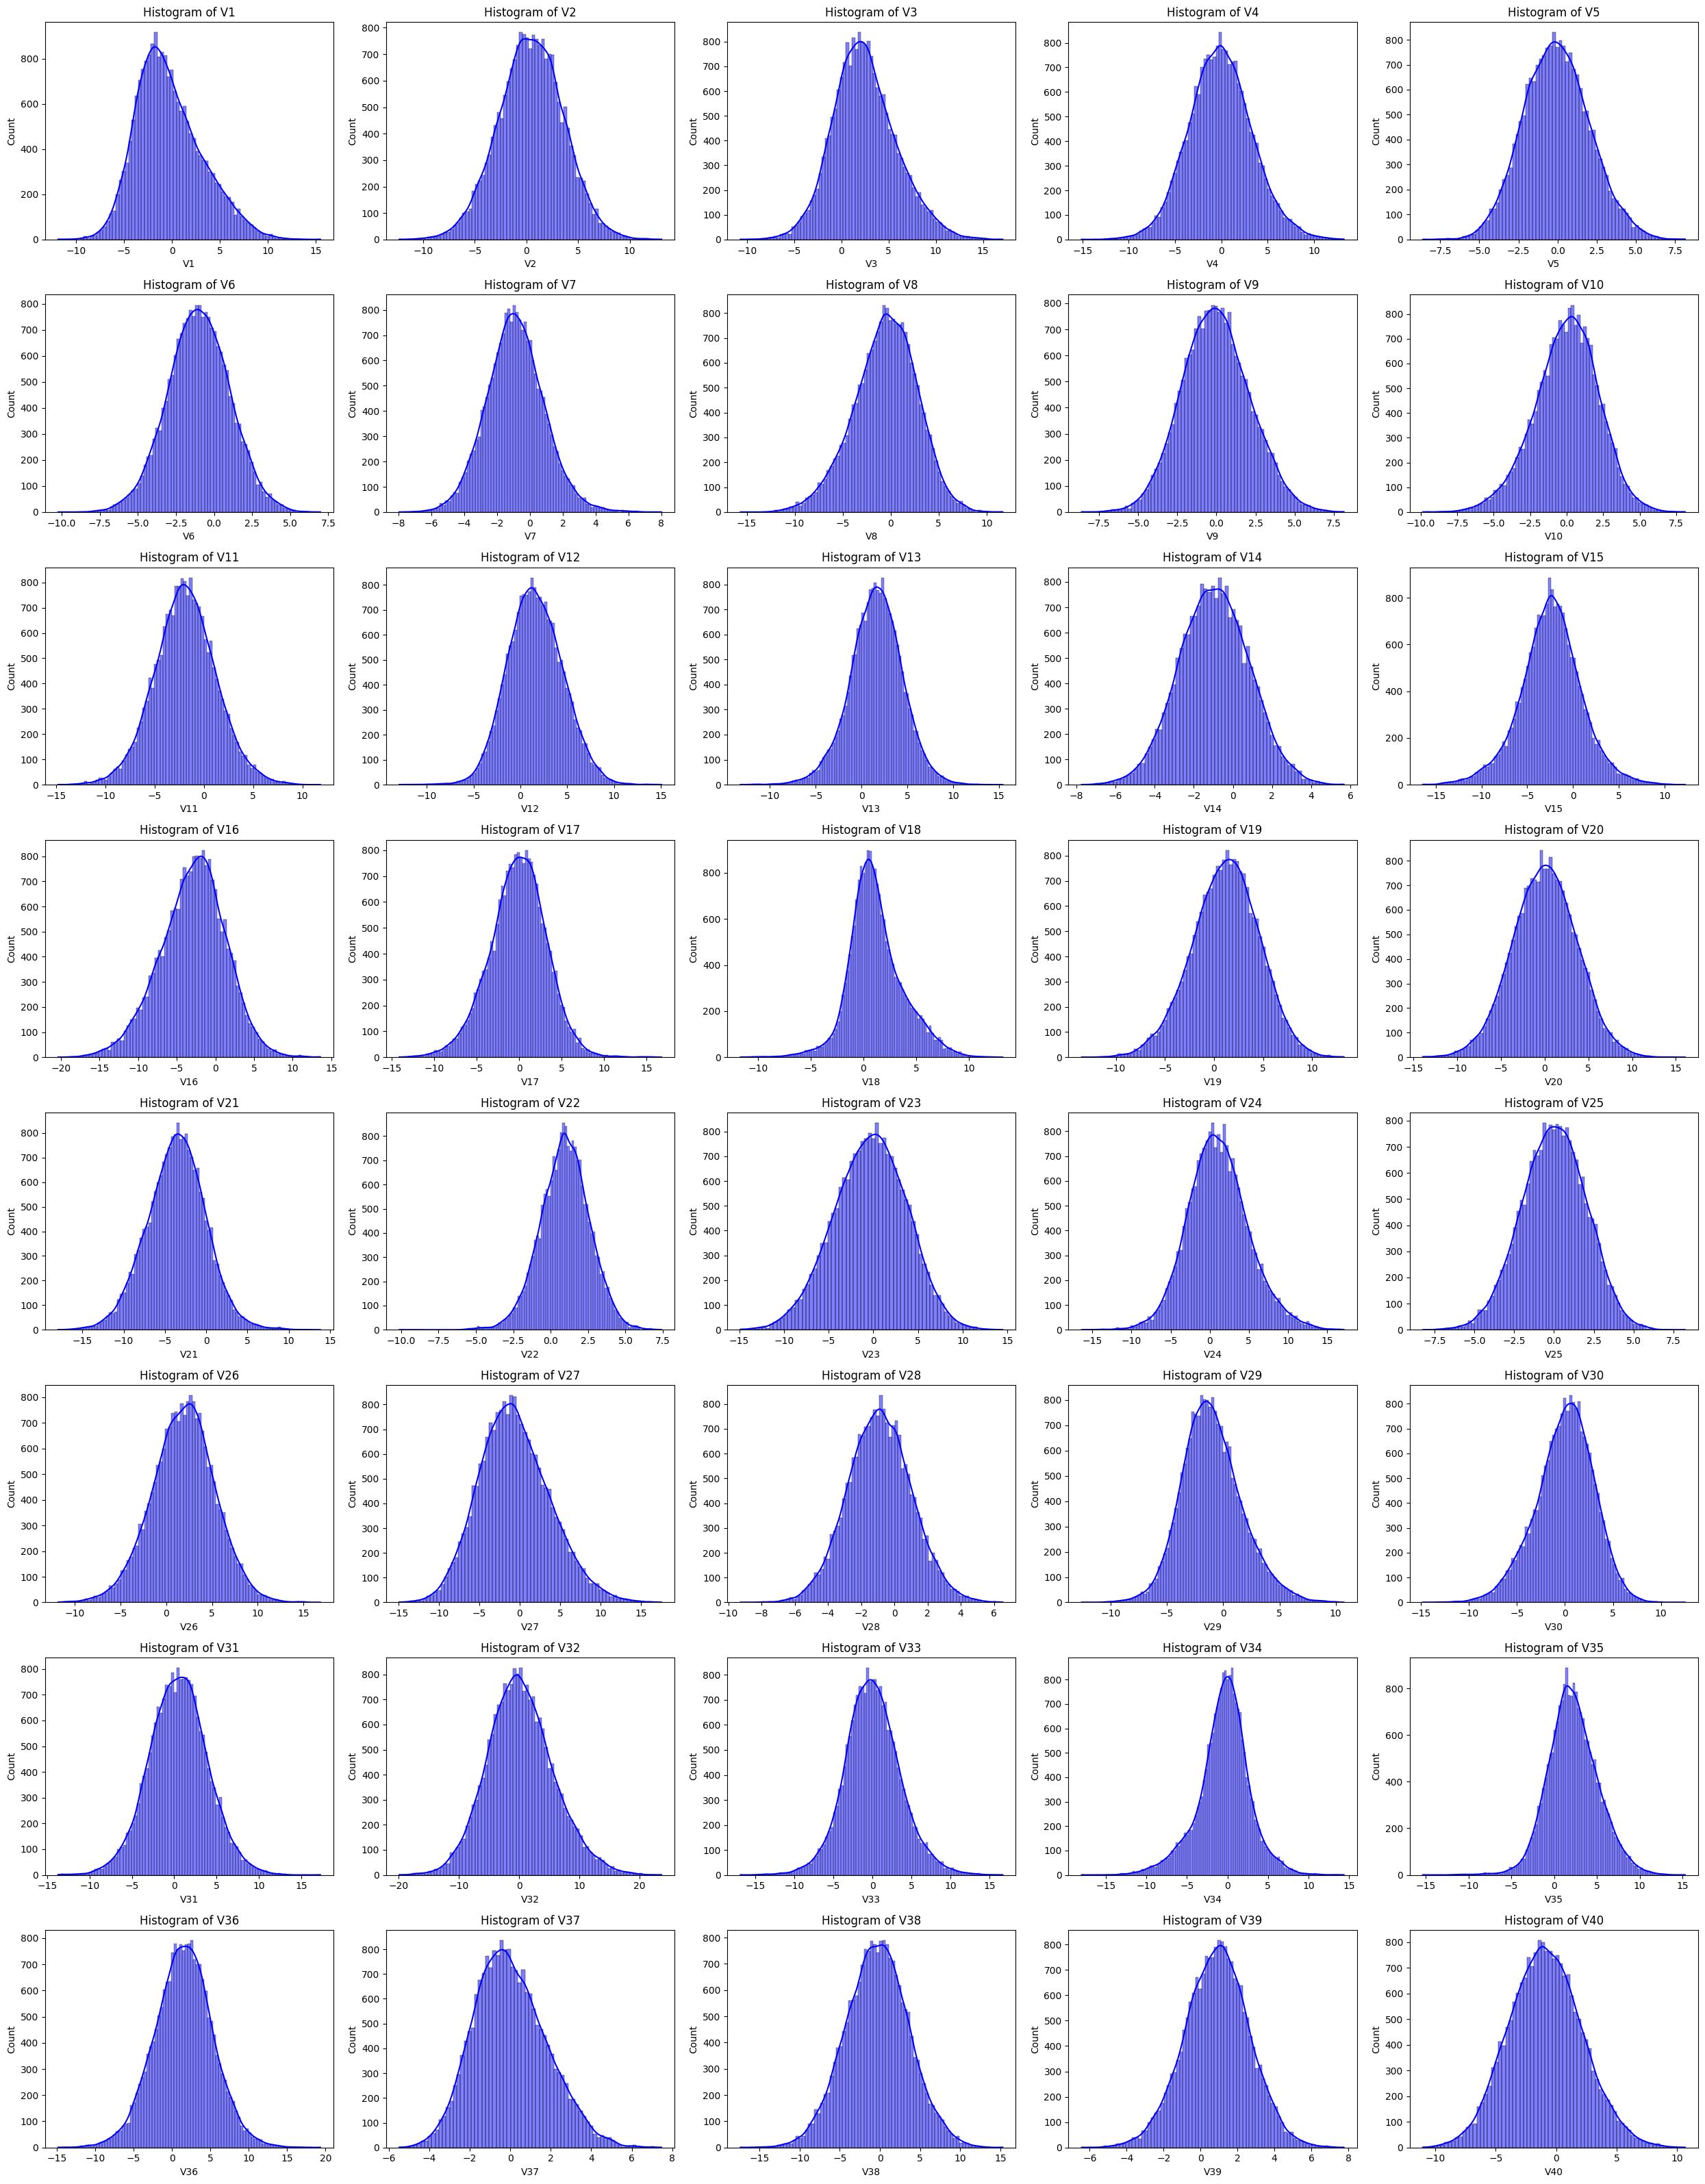

In [101]:
# Create subplot grid
n_cols=5
n_rows = 8
fig, axs = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
axs = axs.flatten()

for i, predictor in enumerate(predictors):
    sns.histplot(data=df_train, x=predictor, kde=True, ax=axs[i], color="blue")
    axs[i].set_title(f"Histogram of {predictor}")

# Hide unused axes if any
for j in range(len(predictors), len(axs)):
    fig.delaxes(axs[j])

plt.tight_layout()
plt.show()


*   **Histogram plots above show that for most of the predictor variables, distributions are closer to normal distribution.**


## Bivariate Analysis

**Unique Target classes**

In [102]:
print('Number of target classes: ', df_train['Target'].nunique())
df_train['Target'].unique()


Number of target classes:  2


array([0, 1], dtype=int64)

**Utility function to plot the histogram and boxplot**

In [103]:
# Utility function to plot the histogram and boxplot
def histplot_boxplot(df, feature, target):
    target_values = df[target].unique()
    target_labels = {1: "Failure", 0: "NoFailure"}
    fig, axs = plt.subplots(1, 3, figsize=(15, 4))
    axs[0].set_title("Distribution of " + feature + "With hue over Target" )
    sns.histplot(
        data=df_train,
        x=predictor,
        hue=target,
        kde=True,
        stat="density",
        common_norm=False,
        element="step",
        palette="muted",
        ax=axs[0],
    )

    axs[1].set_title("Box plot of " + feature + " w.r.t Target")
    sns.boxplot(
        df_train,
        x=target,
        y=feature,
        hue=target,
        legend=False,
        ax=axs[1],
        palette="muted",
    )
    axs[2].set_title("Box plot of " + feature + " w.r.t Target and Without Outliers")
    sns.boxplot(
        df_train,
        x=target,
        y=feature,
        ax=axs[2],
        showfliers=False,
        hue=target,
        legend=False,
        palette="muted",
    )

    plt.tight_layout()
    plt.show()

### Histograms and Box plots showing the distribustions of Predictors

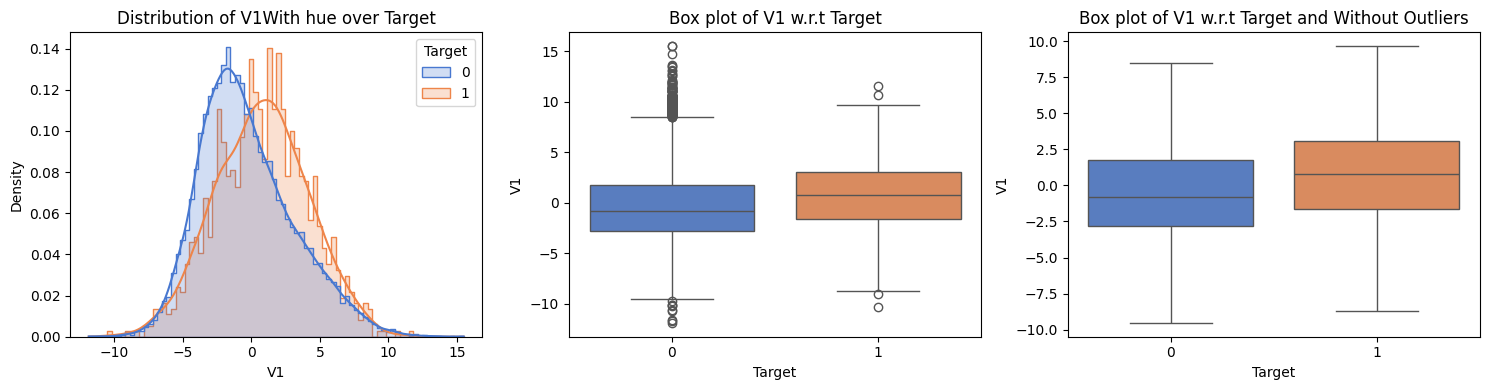

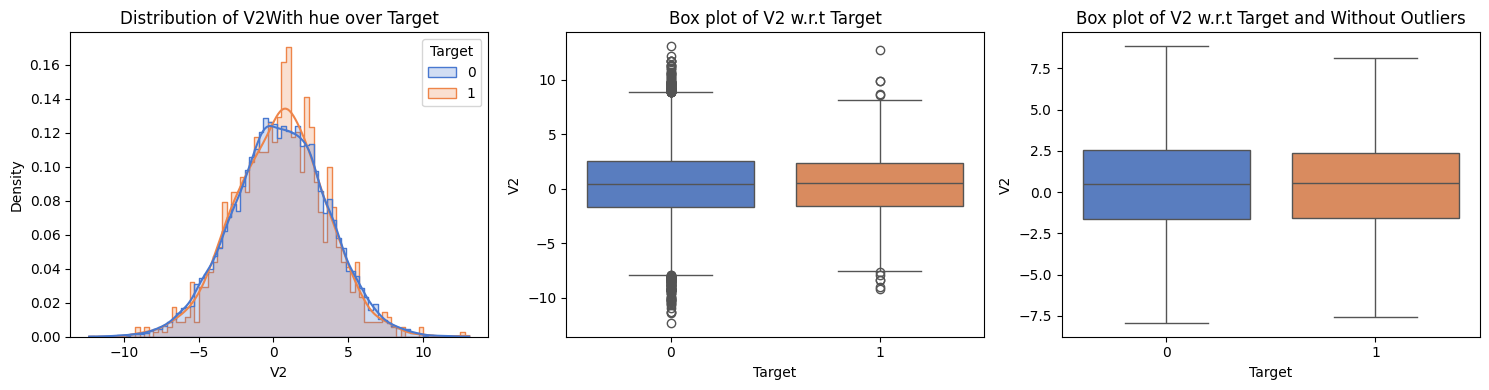

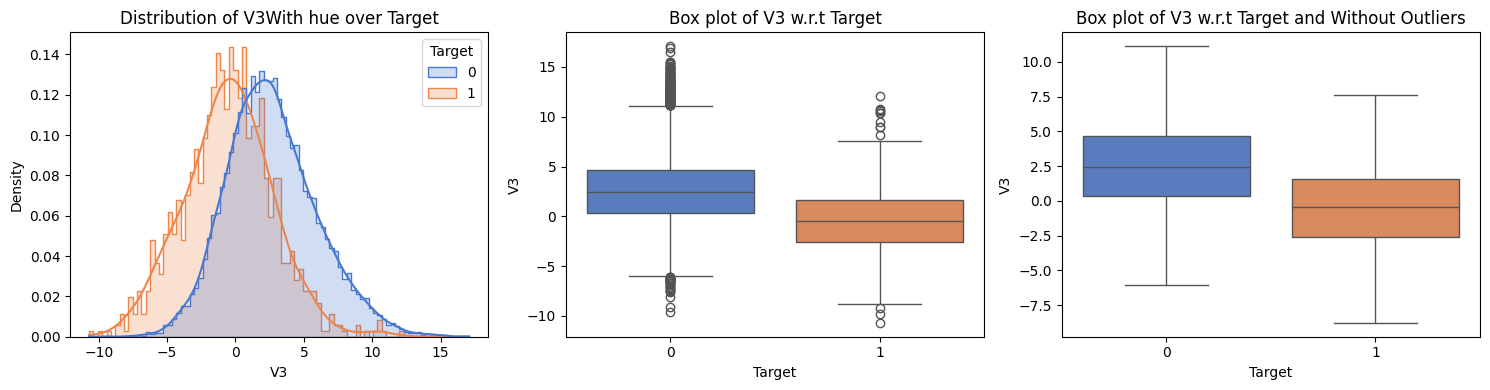

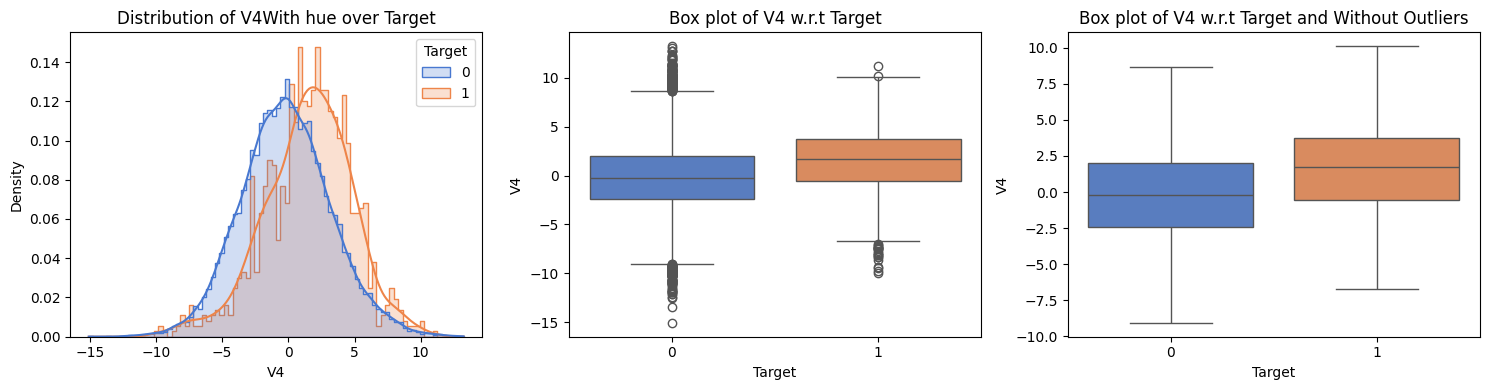

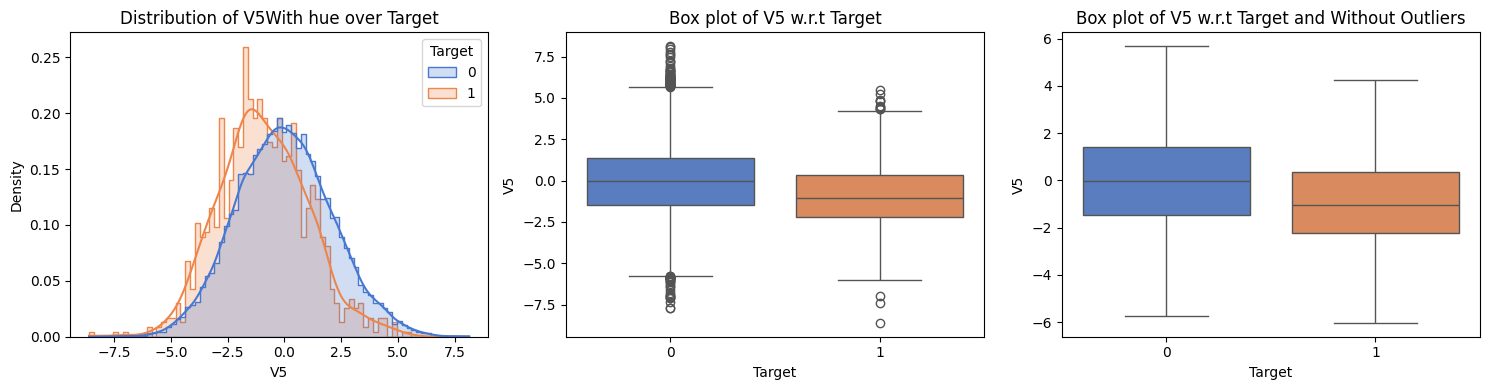

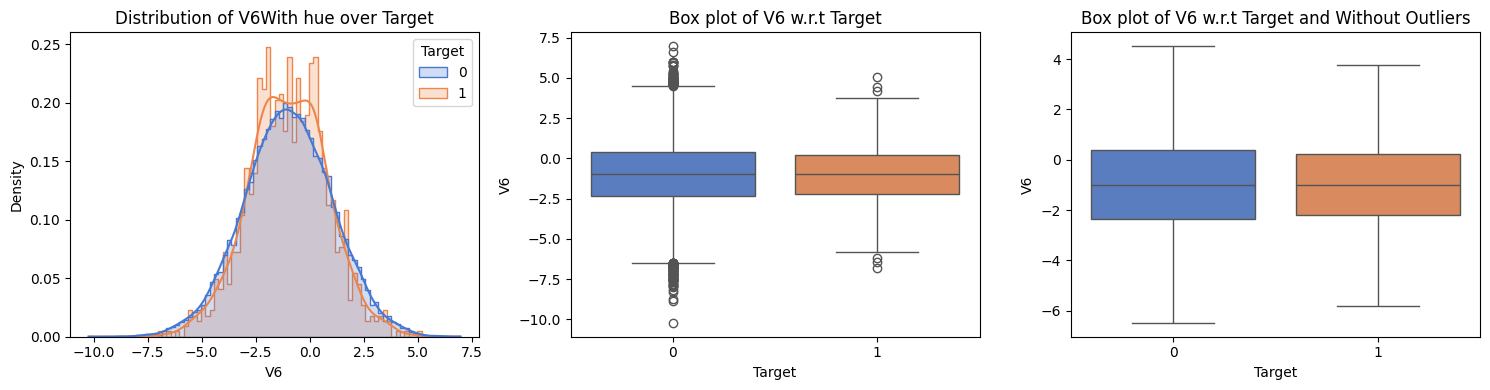

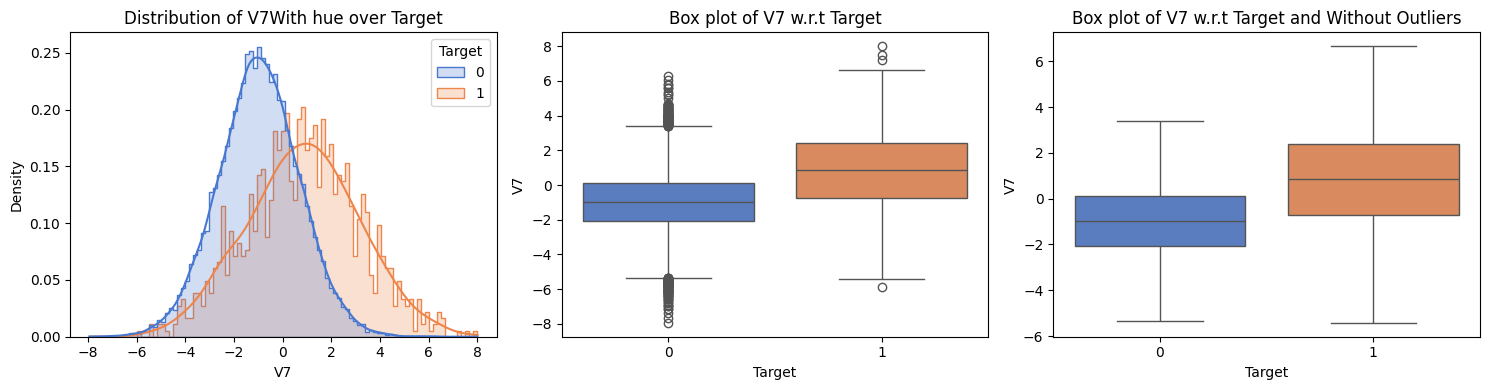

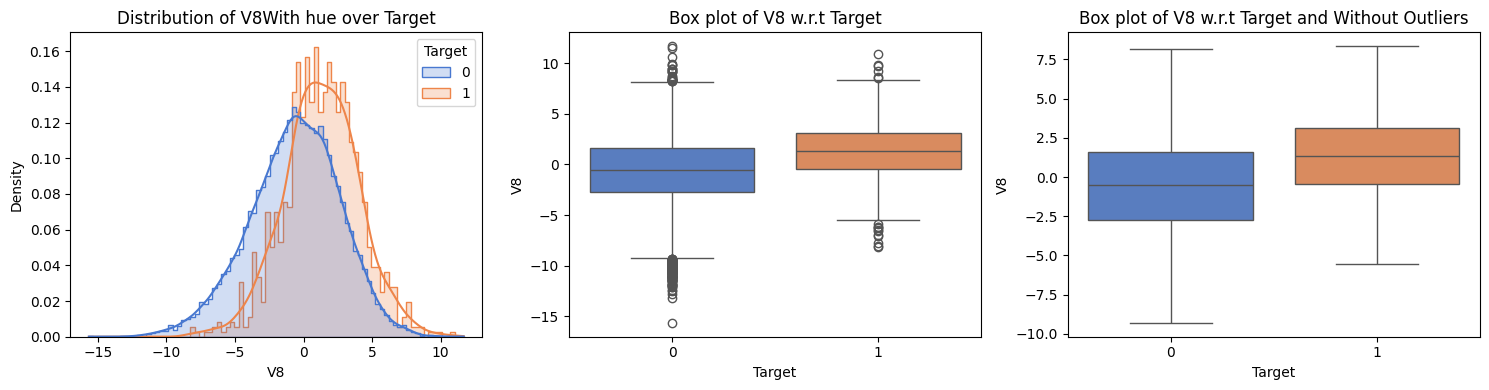

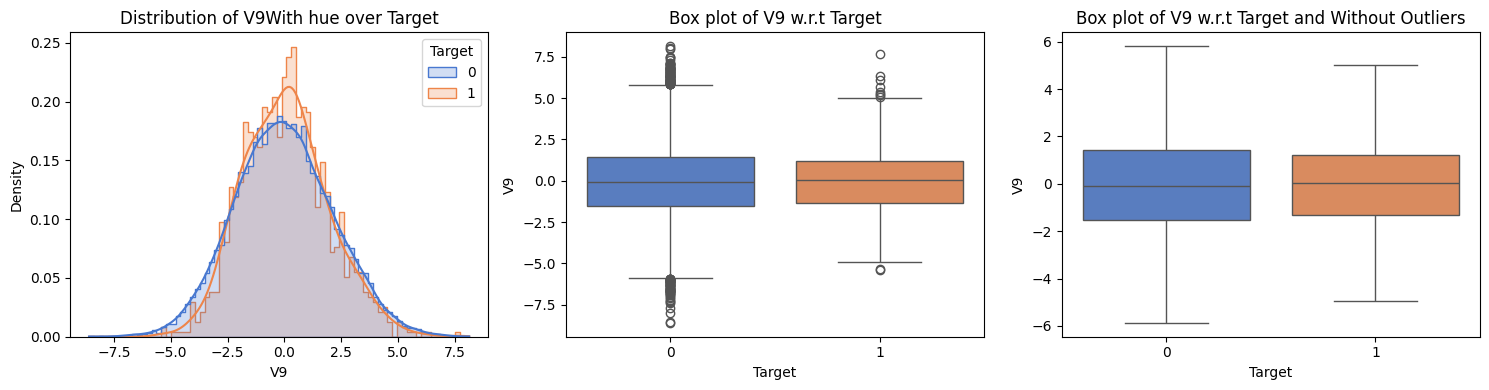

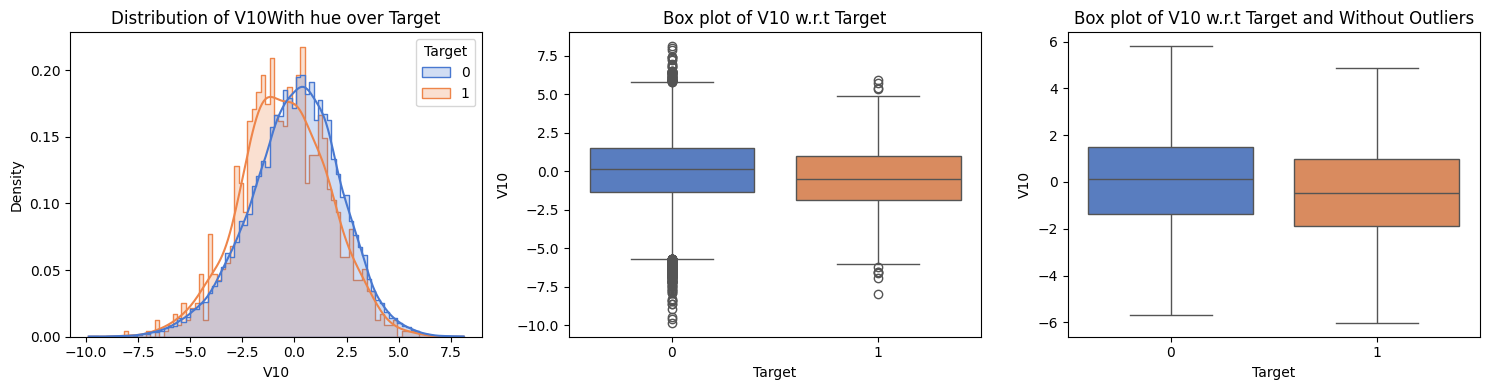

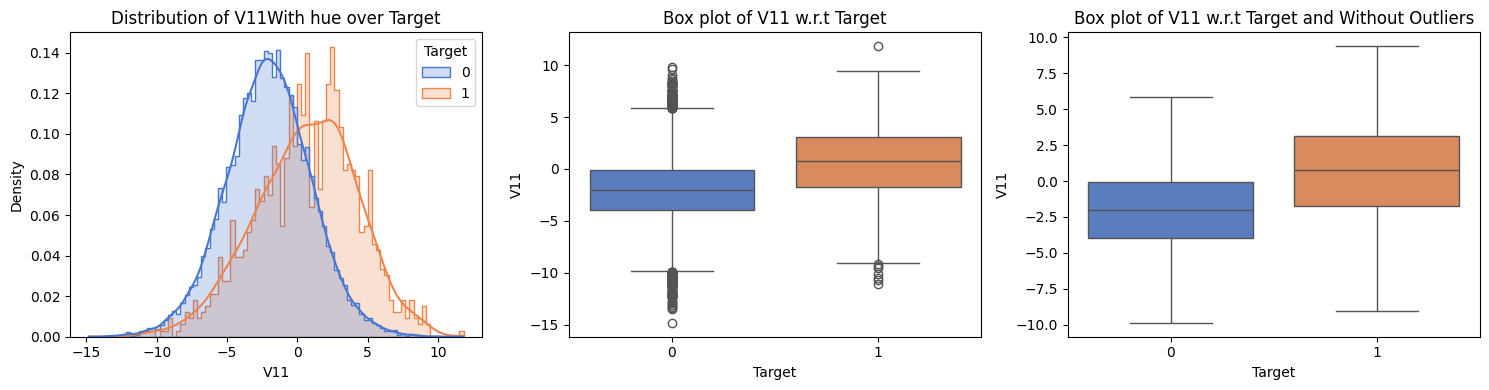

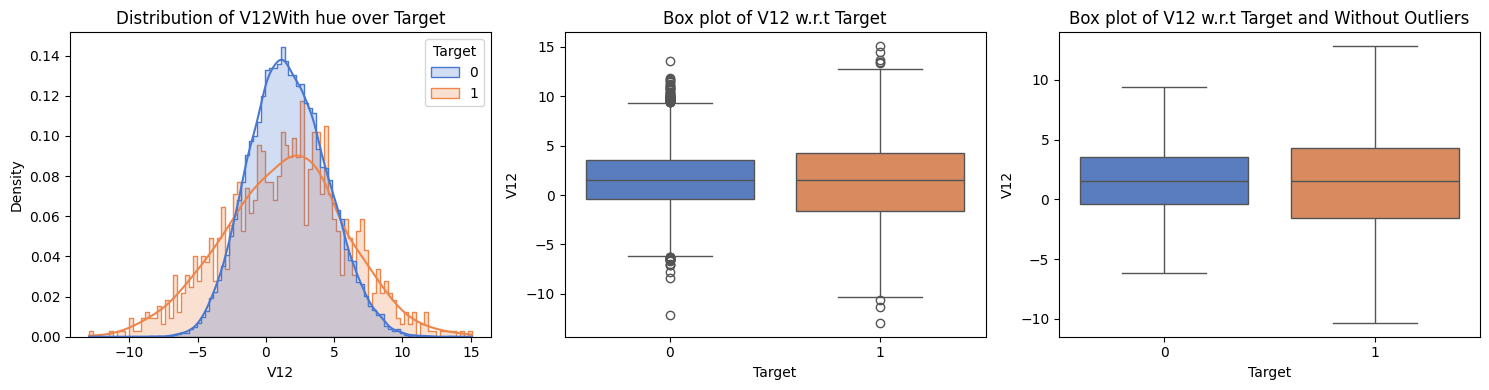

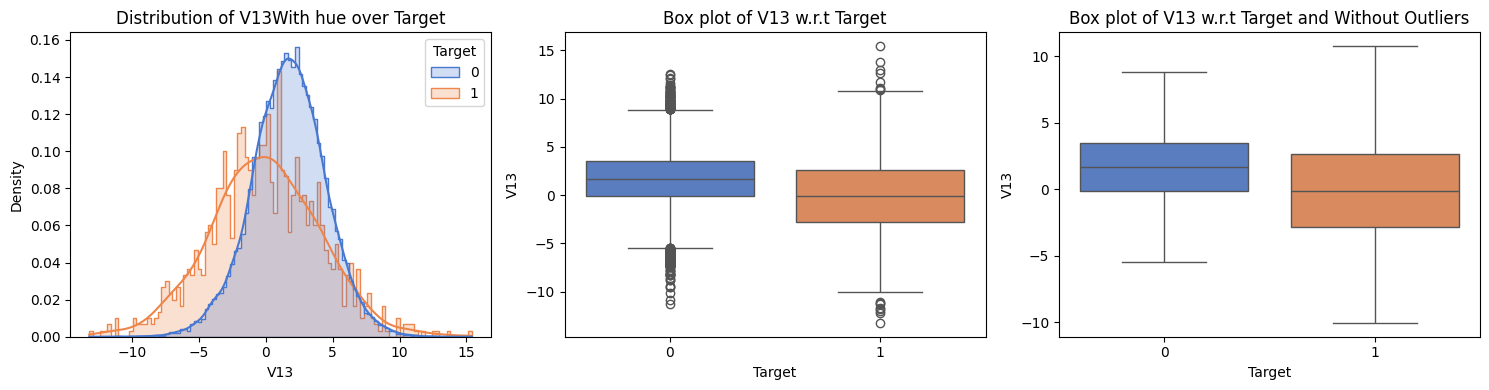

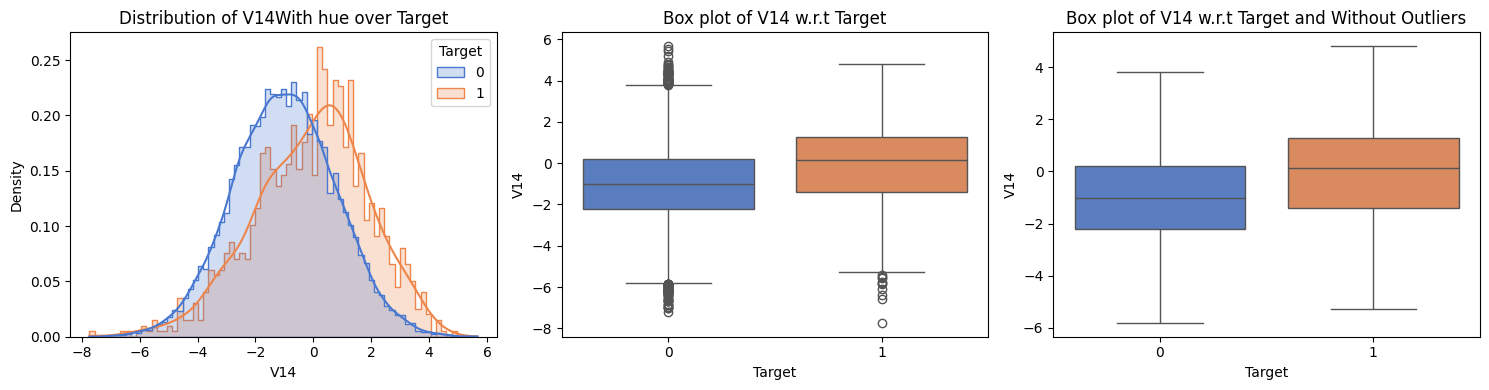

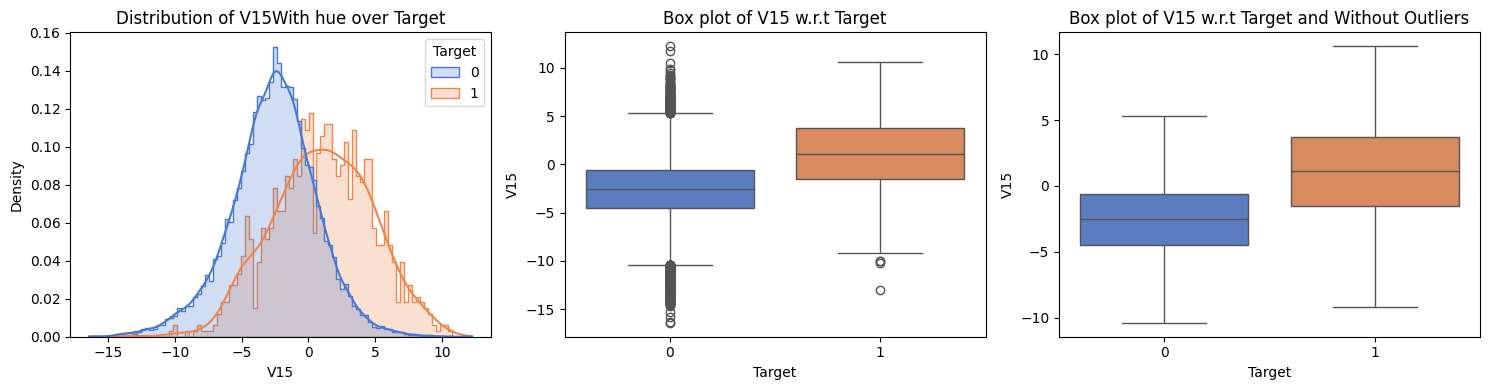

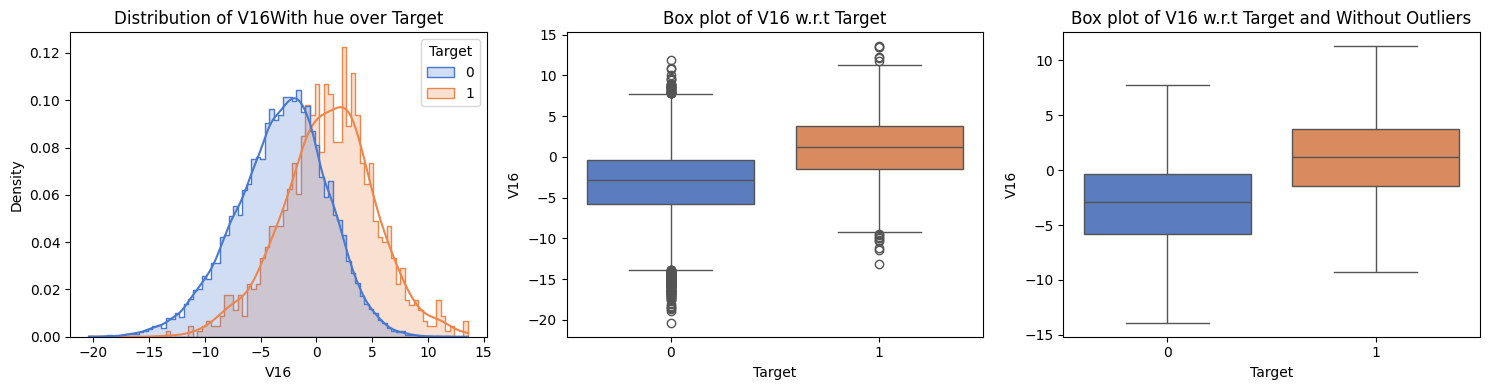

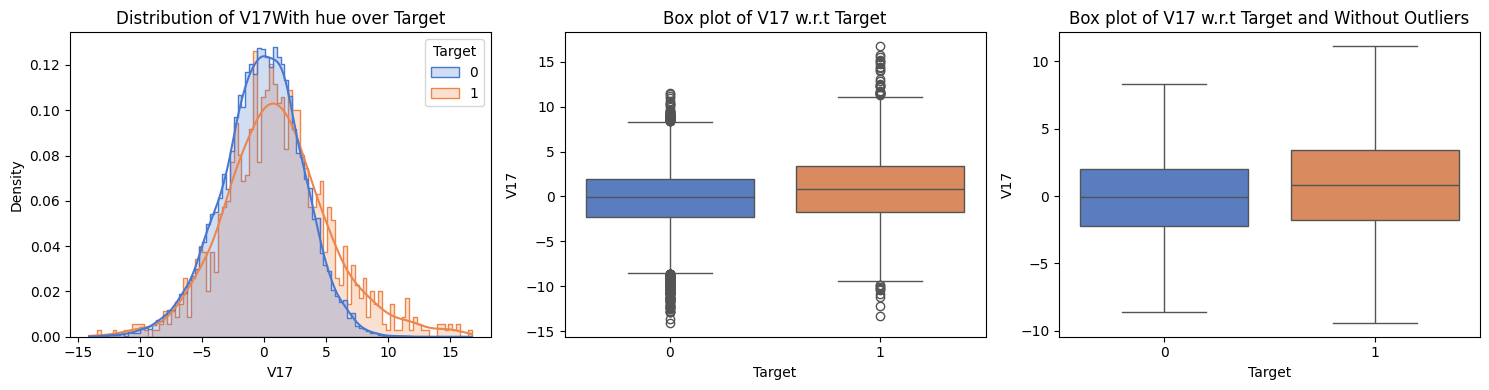

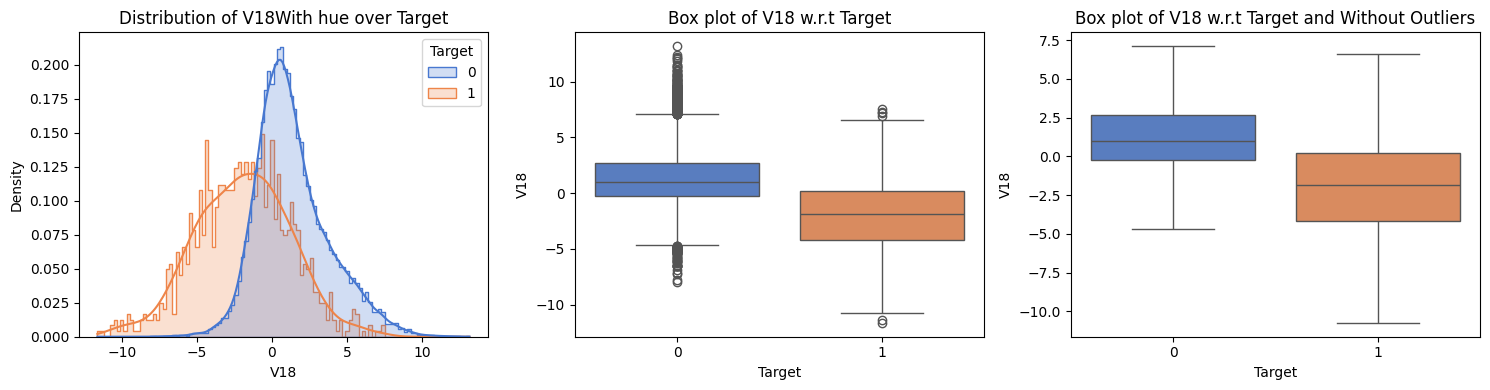

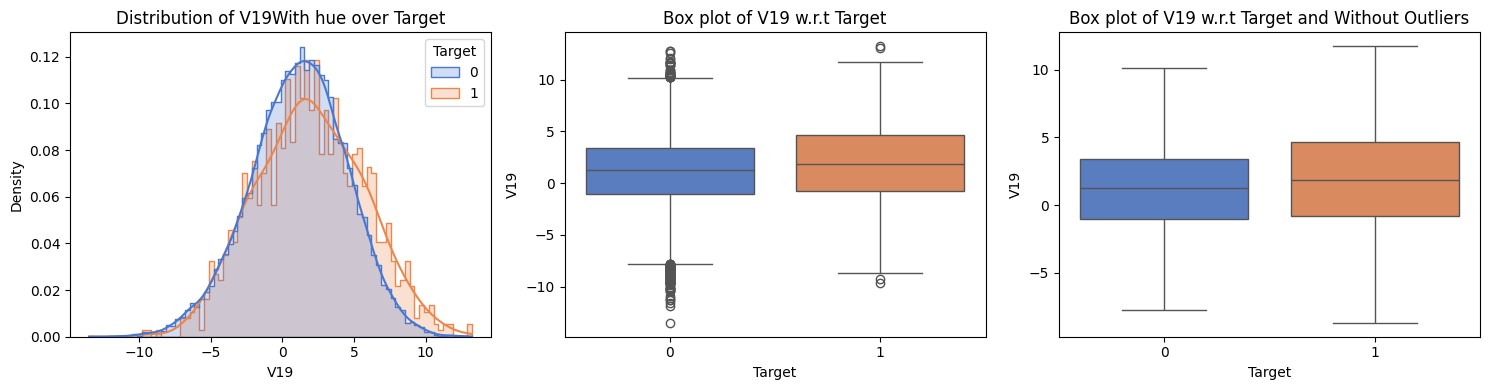

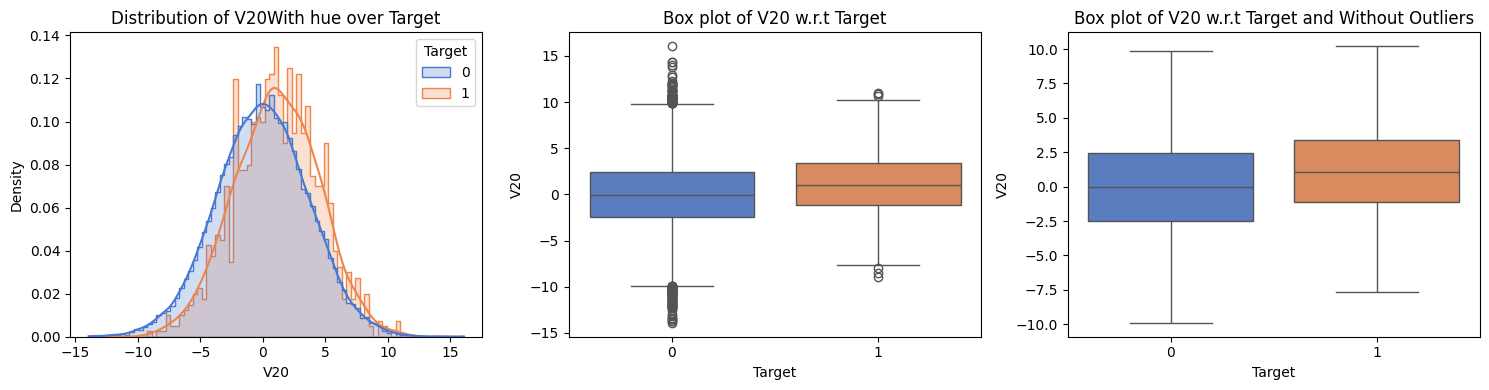

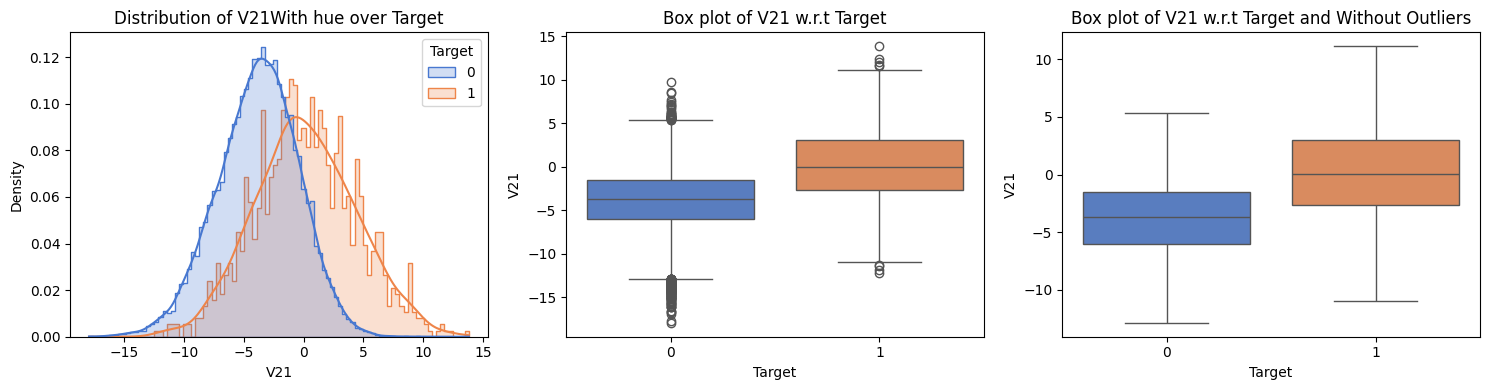

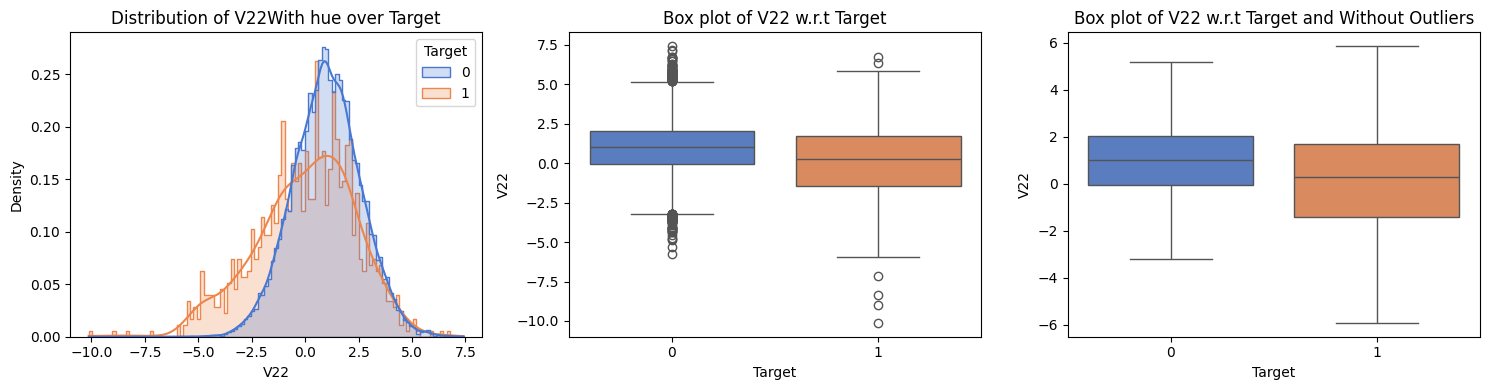

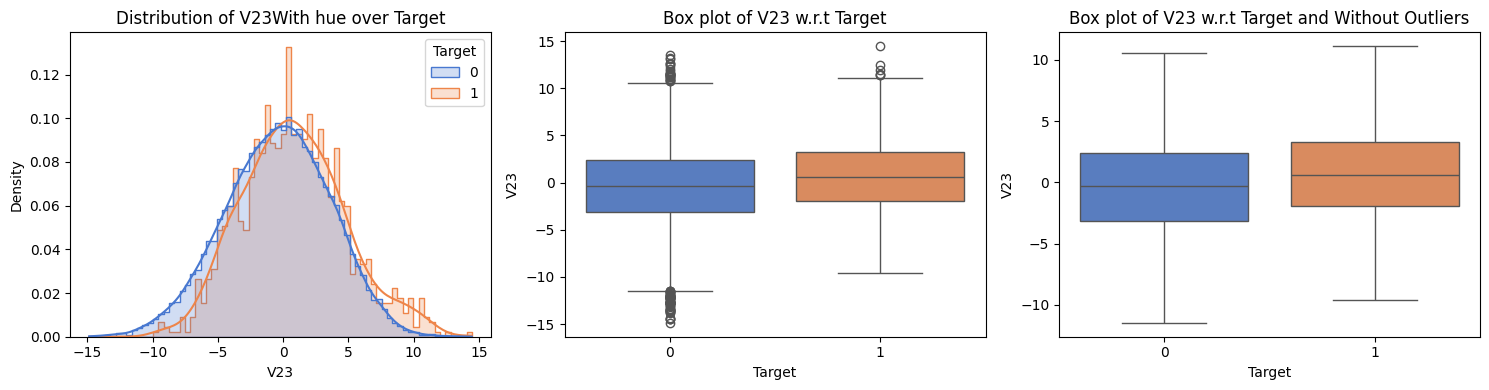

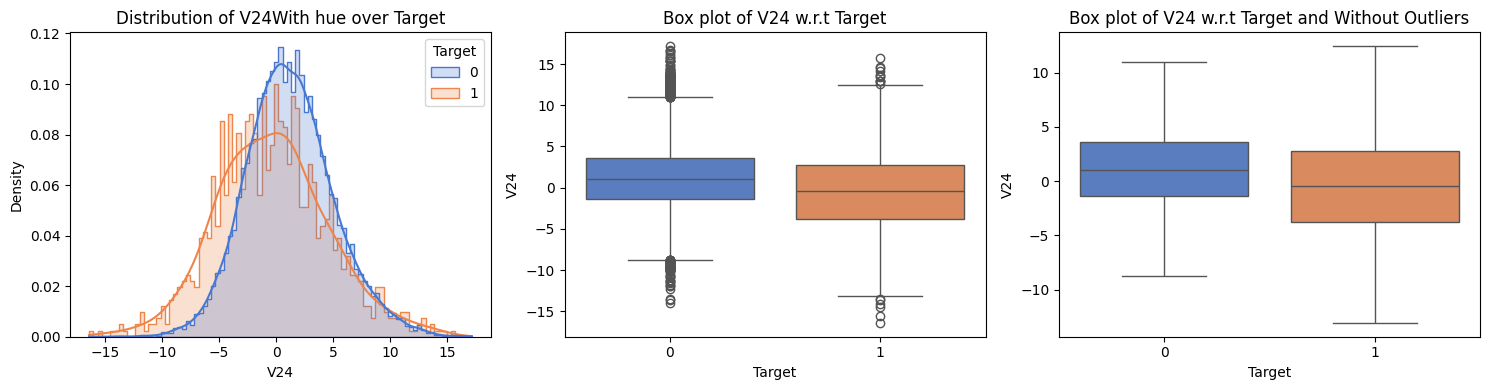

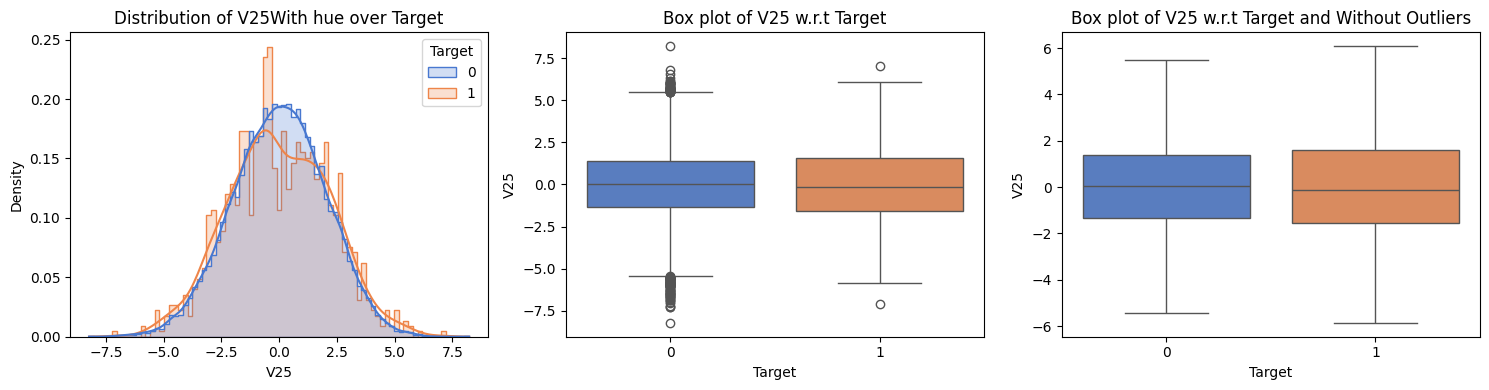

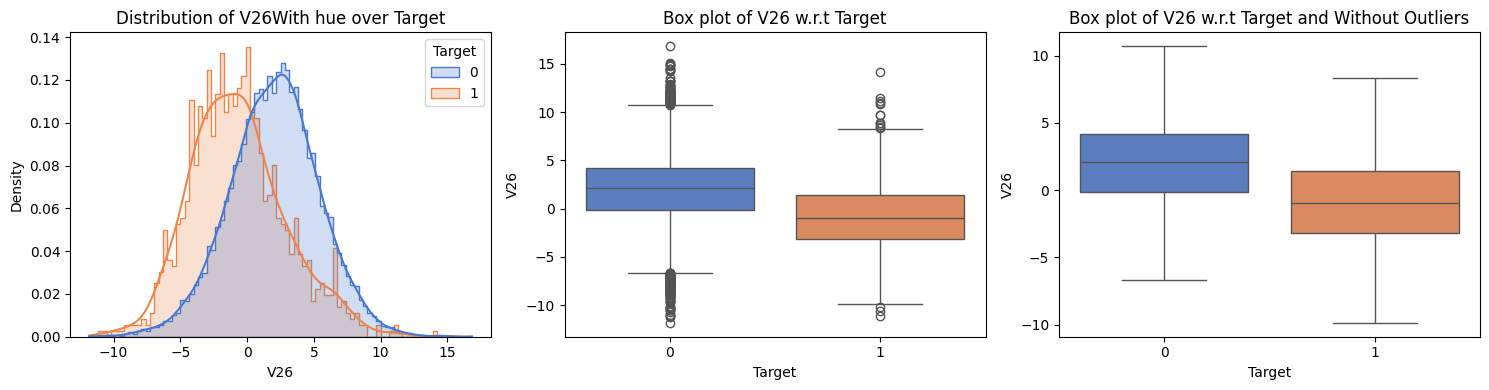

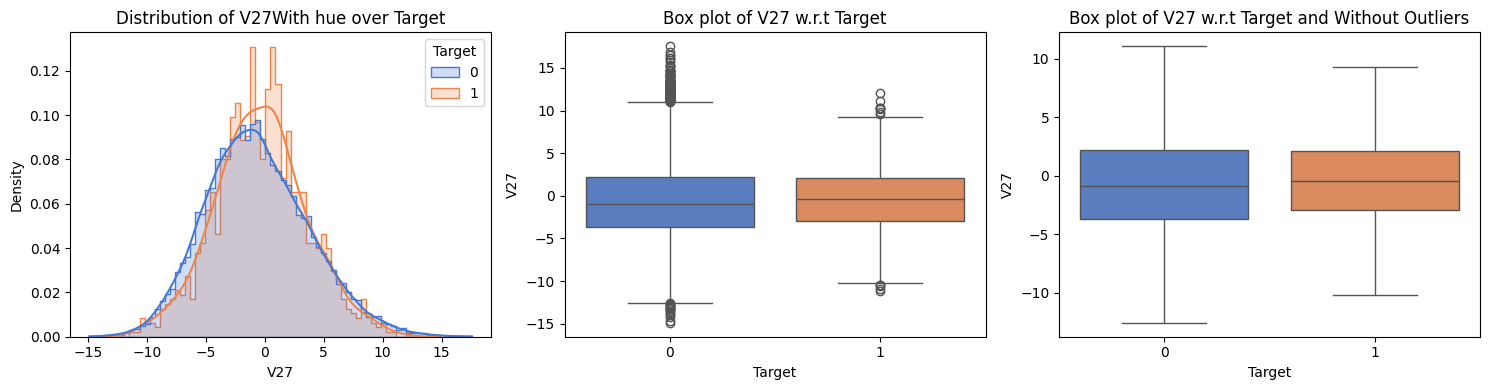

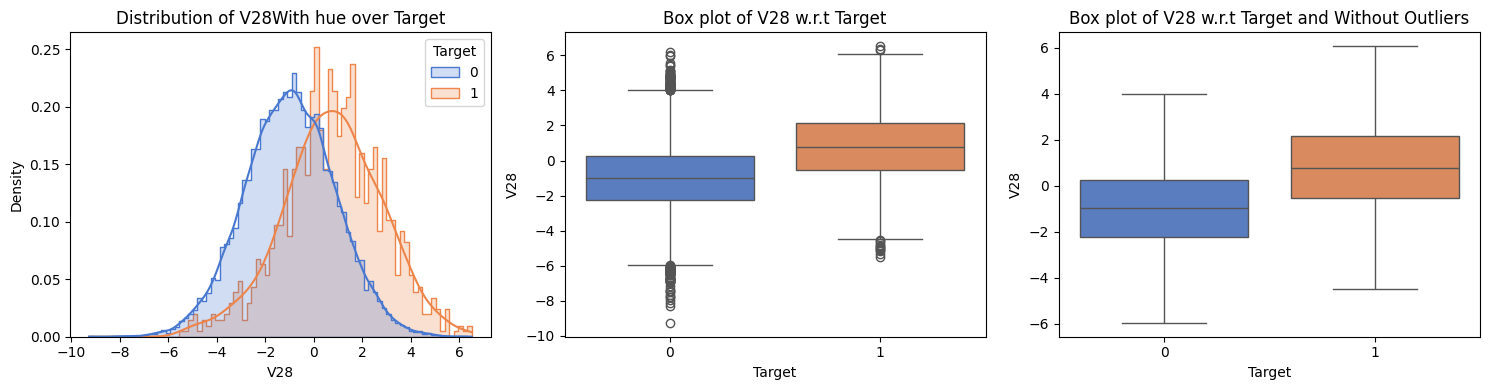

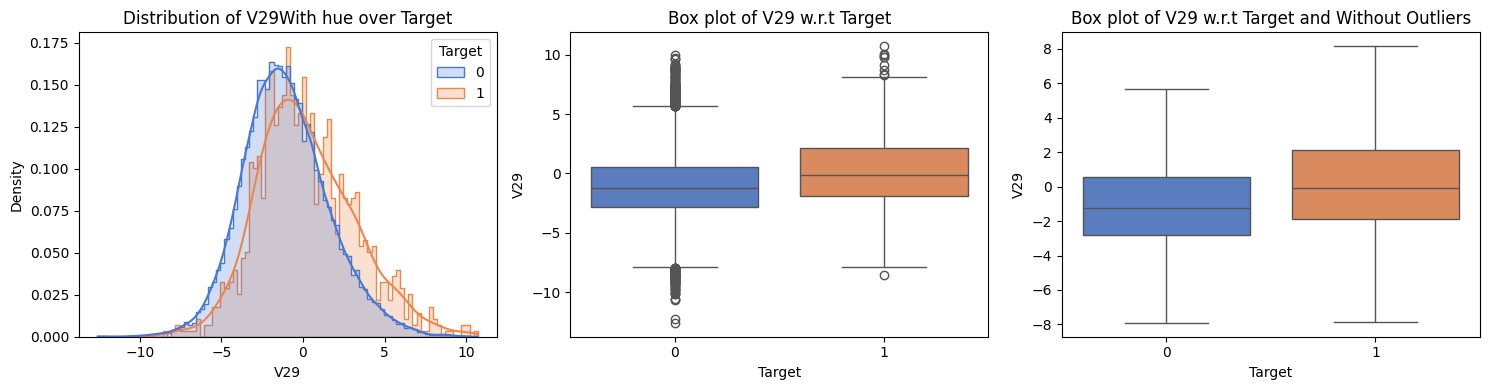

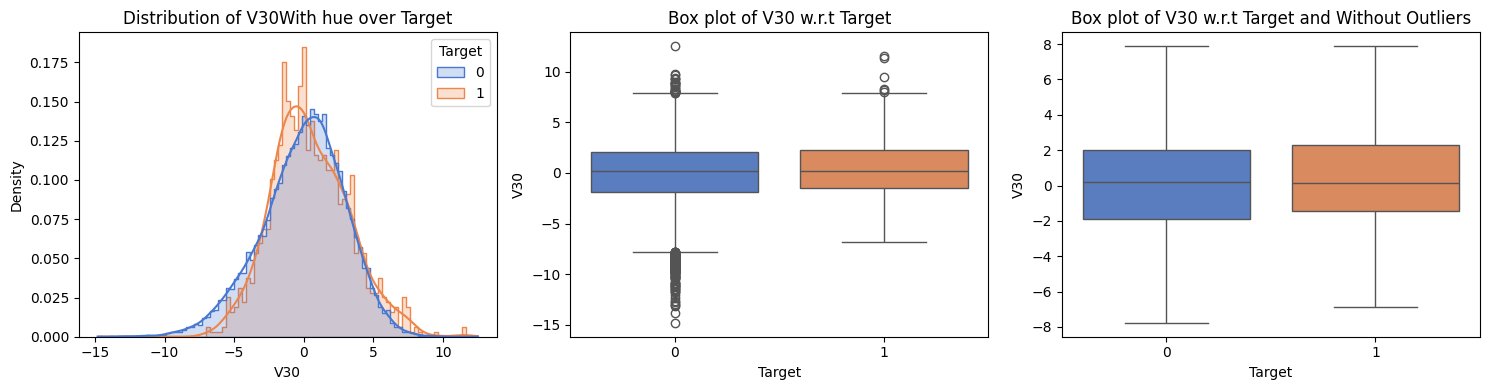

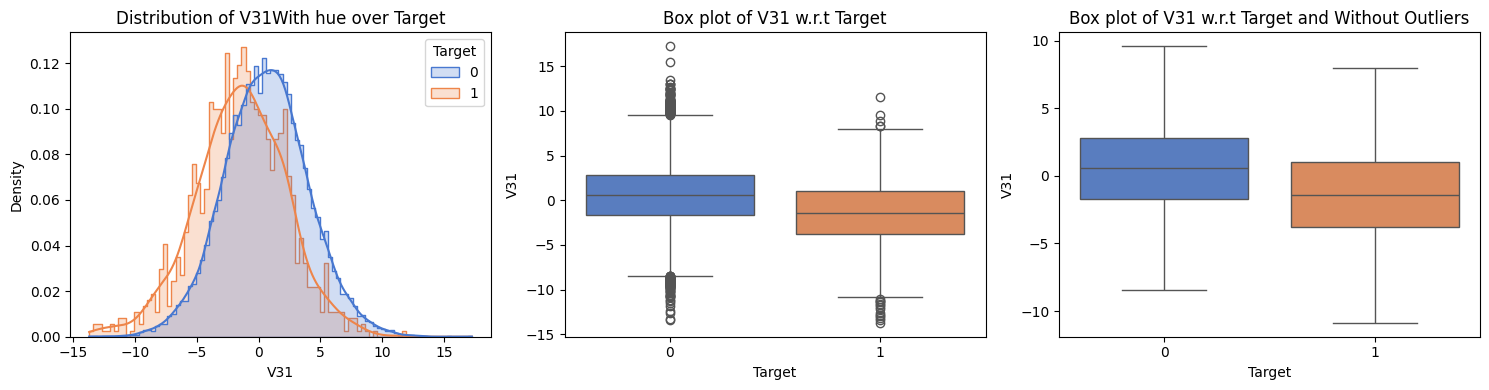

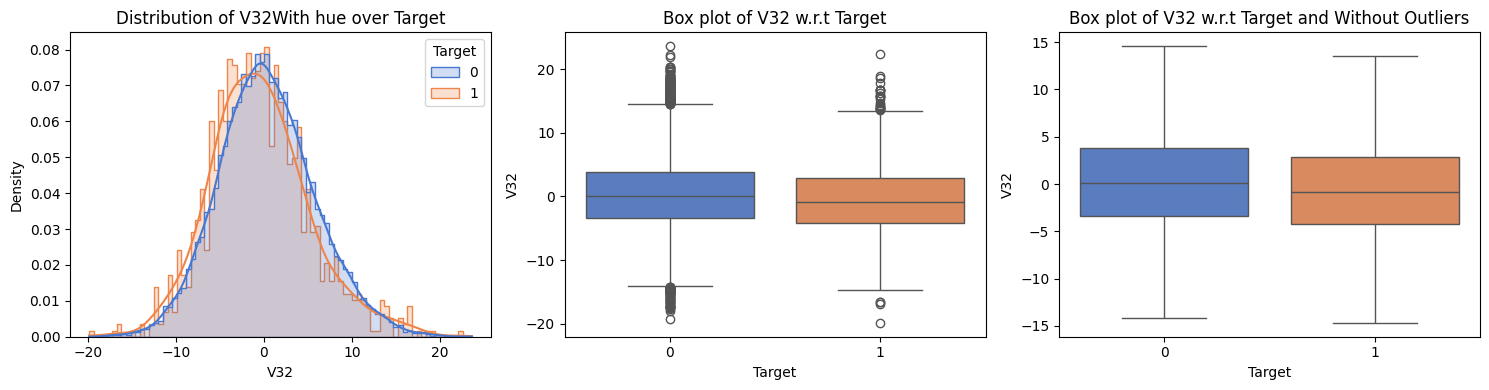

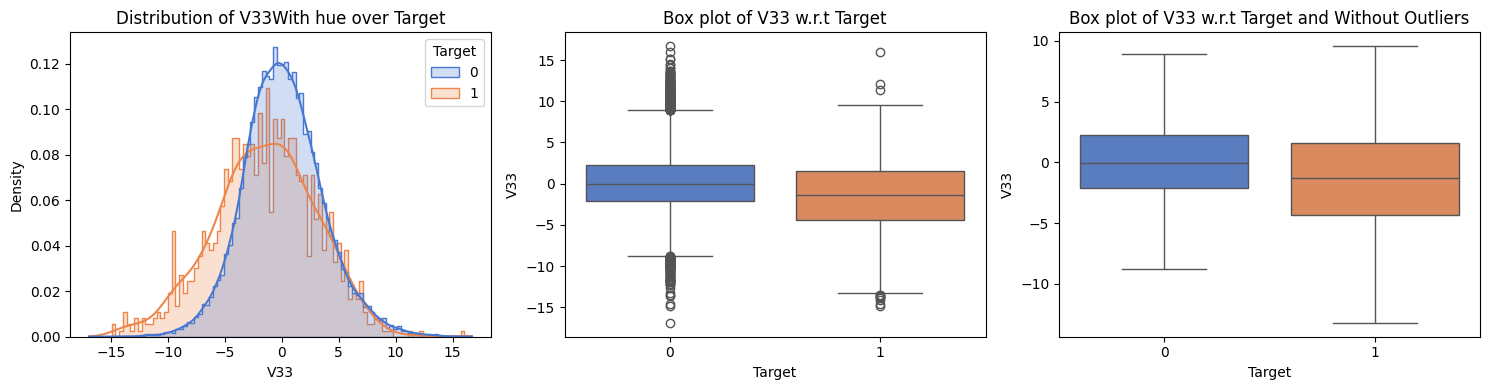

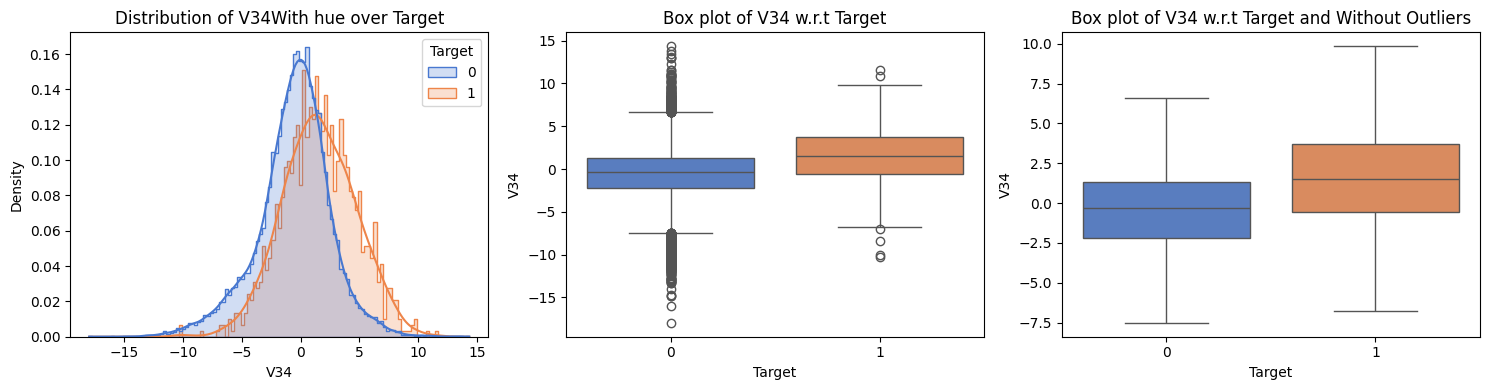

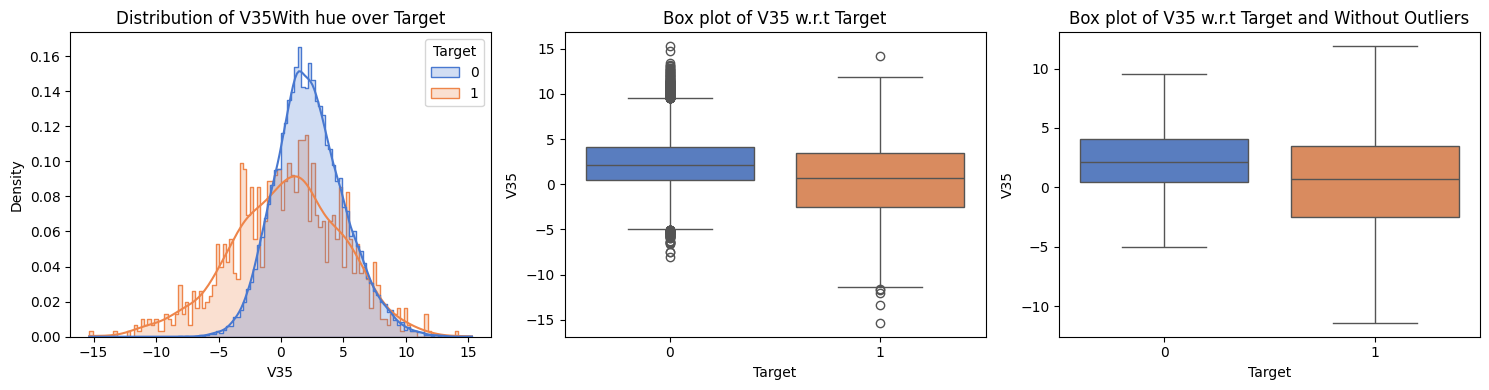

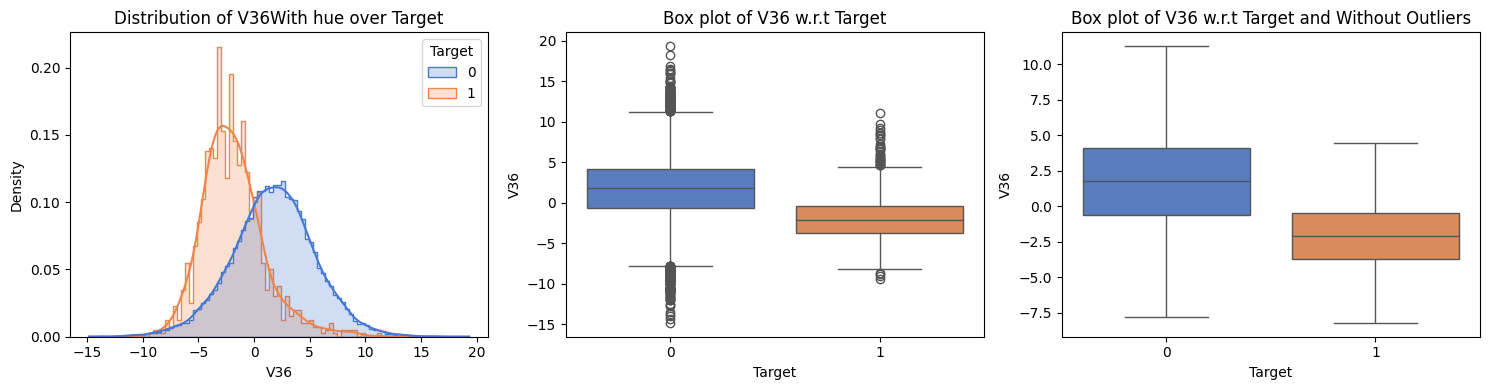

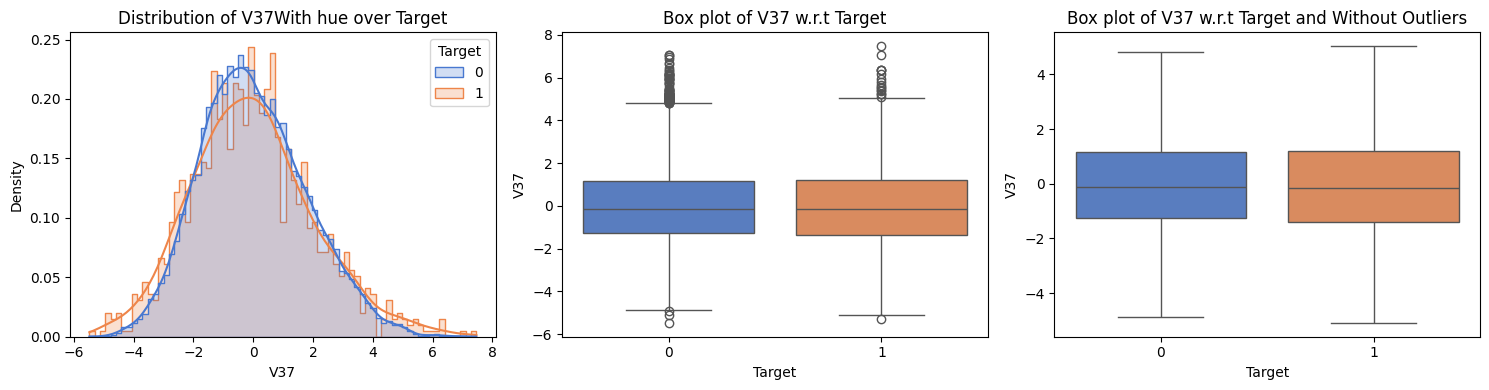

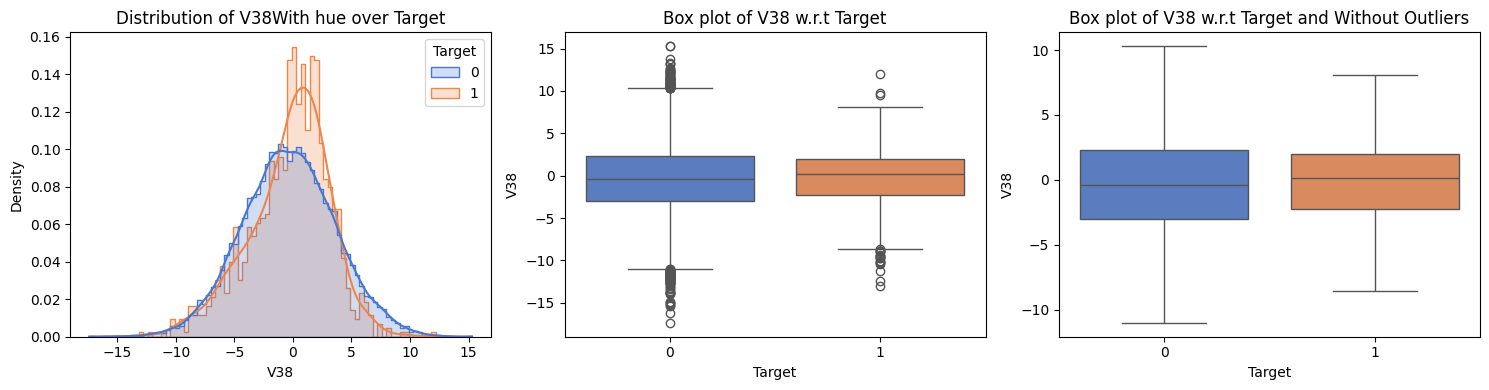

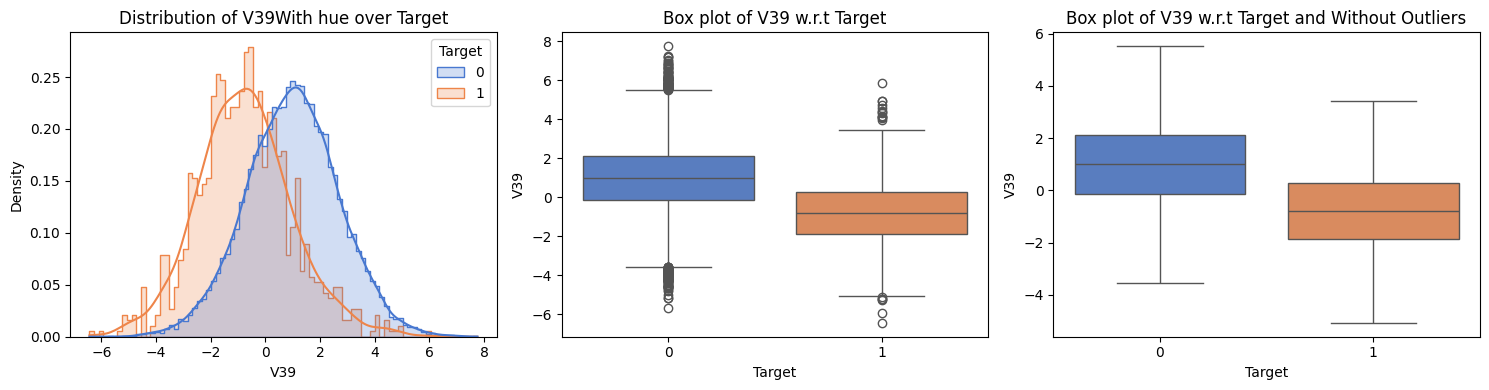

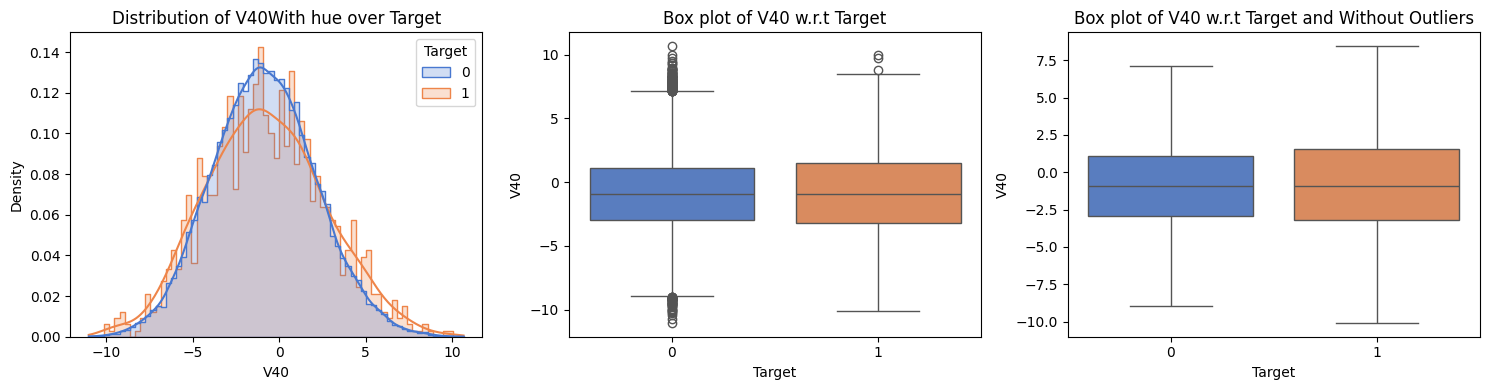

In [104]:
for predictor in predictors:
    histplot_boxplot(df_train, predictor, "Target")

### Insight on Predictive Value of Predictor Variables

- Histogram and Box plots above show the **predictive value** of the predictor variables on Target class prediction. In other words, how helpful the particular feature is in predicting the target class.

- Some predictor variables show much similar distributions among the two target classes, (Failure and No Failure), more overlap in histograms and closer median values and quartiles in box plots. These will have very less or no significant influence over the target variable and might not help much in the classification.

- In the given dataset, these are :
 V2, V6, V9, V12, V17, V19, V20, V23, V25, V27, V30, V37, V38, V40

- On the otehr hand, for some variables, the distributions of Target value 0 (No Failure class)  and Target Value 1 (Failure class) show shifts in central tendency and not much overlap in histograms indicating comparitively higher predictive value of those variables.

- For such predictors, comparison of the box plots of Target value 0 (No Failure class) and Target Value 1 (Failure class) also show the differences in median values and quartiles, again indicating the higher predictive value. These features might help more in the classification.


- **Variables that have influence on Target variable are:**

- V1, V3, V4, V5, V7, V8, V10, V11, V13, V14, V15, V16, V18, V21, V22, V24, V26, V28, V29, V31, V32, V33, V34, V35, V36, V39.

- Among these variables, the following had lower median for Target class 1  (Failure class) compared to Target calss 0 (No Failure). Histogram Peak of the Failure class distribution is on the left.
So, for these variables, **lower values associate with potential failure**.

- V3, V5, V10, V13, V18, V22, V24, V26, V31, V33, V35, V36, V39


- The following variables have Higher Median for Target class 1 (Failure class) and its Histogram Peak is on the right.  
For these predictors, Higher values are most likely lead to potential failure.
**bold text**
- V1, V4, V7, V8, V11, V14, V15, V16, V21, V28, V29, V34


### Outliers Presence

- Many predictors have some outliers, however, these outliers most likey be realistic values as they appear as just an extension beyond the whiskers.
Hence, no special treatment of outliers may be necessary.

### Pairplot showing the relationship among the variables

In [105]:
#plt.figure(figsize=(20,20))
#sns.pairplot(df_train, hue='Target')
#plt.show()

### Correlation among the variables - Heatmap

<Axes: >

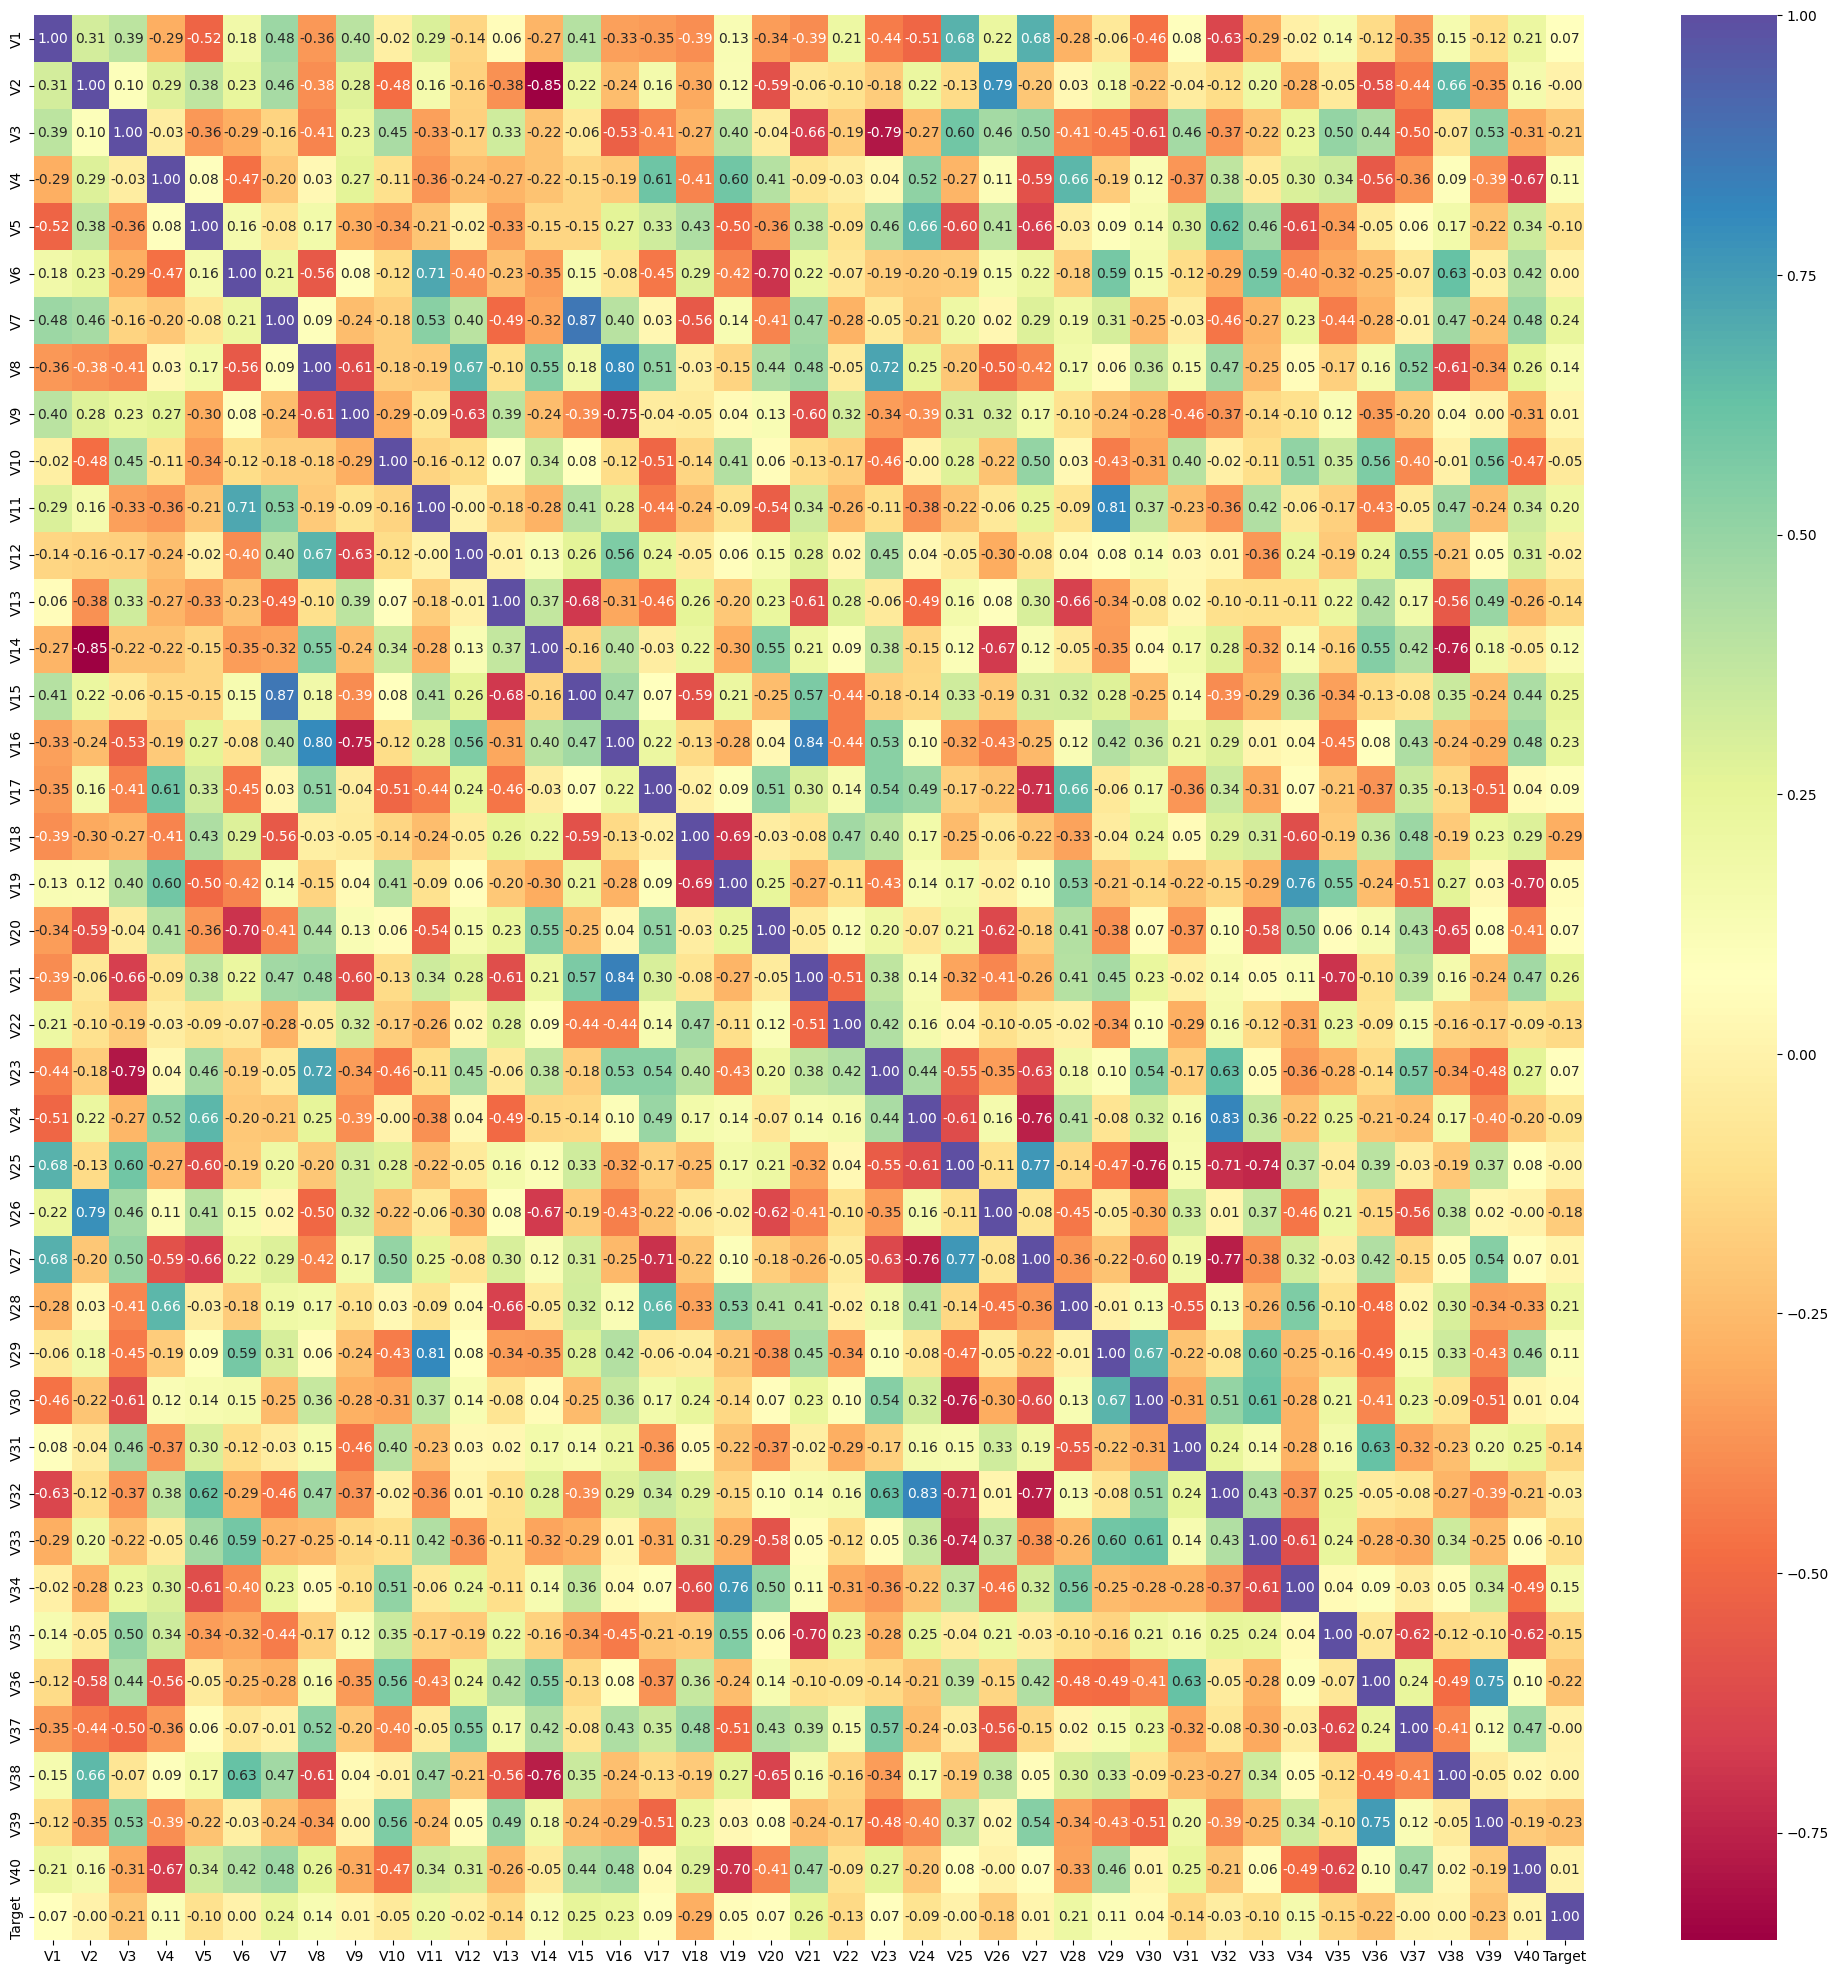

In [106]:
plt.figure(figsize=(25,25))
sns.heatmap(df_train.corr(), annot=True, fmt='0.2f',cmap='Spectral')



- There appears to be a few highly correlated features with some values higher than 0.8.
- In general, this correlation may not be a serious problem for neural network models.
- However, if there are convergence or overfitting problems, it may be a better idea to use regularization esp. **L1(LASSO) regularization** which helps in feature selection as well and reduces overfitting.

# Data Preparation for Modeling

### Numerical columns

In [107]:
numeric_cols = df_train.select_dtypes(include=np.number).columns.to_list()
print("Number of numeric columns: ",len(numeric_cols))

Number of numeric columns:  41


- All the columns are numerical columns. Hence no need to treat them separately.

### Separate Independent and Dependent Variables

In [108]:
X = df_train.drop("Target", axis=1)
y = df_train["Target"]
print(f"X: {X.shape}, y: {y.shape}")


X: (20000, 40), y: (20000,)


In [109]:
X_test = df_test.drop("Target", axis=1)
y_test = df_test["Target"]
print(f"X_test: {X_test.shape}, y_test: {y_test.shape}")


X_test: (5000, 40), y_test: (5000,)


### Split the Train Data into train and validation data

In [110]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=1
)

In [111]:
print(f' X_train: {X_train.shape}, y_train: {y_train.shape}')
print(f' X_val  : {X_val.shape}, y_val={y_val.shape}')
print(f" X_test : {X_test.shape}, y_test: {y_test.shape}")

 X_train: (15000, 40), y_train: (15000,)
 X_val  : (5000, 40), y_val=(5000,)
 X_test : (5000, 40), y_test: (5000,)


# **Data Preprocessing**

## Check for Missing Values

In [112]:
#Missing values in the Train data set - Features
X_train.isnull().sum()

V1     15
V2     14
V3      0
V4      0
V5      0
V6      0
V7      0
V8      0
V9      0
V10     0
V11     0
V12     0
V13     0
V14     0
V15     0
V16     0
V17     0
V18     0
V19     0
V20     0
V21     0
V22     0
V23     0
V24     0
V25     0
V26     0
V27     0
V28     0
V29     0
V30     0
V31     0
V32     0
V33     0
V34     0
V35     0
V36     0
V37     0
V38     0
V39     0
V40     0
dtype: int64

In [113]:
# Missing values in the Train data set - Target variable
y_train.isnull().sum()

0

In [114]:
# Missing values in the Validation data set - Features
X_val.isnull().sum()

V1     3
V2     4
V3     0
V4     0
V5     0
V6     0
V7     0
V8     0
V9     0
V10    0
V11    0
V12    0
V13    0
V14    0
V15    0
V16    0
V17    0
V18    0
V19    0
V20    0
V21    0
V22    0
V23    0
V24    0
V25    0
V26    0
V27    0
V28    0
V29    0
V30    0
V31    0
V32    0
V33    0
V34    0
V35    0
V36    0
V37    0
V38    0
V39    0
V40    0
dtype: int64

In [115]:
# Missing values in the Validation data set - Target
y_val.isnull().sum()

0

### Test data - Missing values

In [116]:
# Missing values in the Test data set - Features
X_test.isnull().sum()

V1     5
V2     6
V3     0
V4     0
V5     0
V6     0
V7     0
V8     0
V9     0
V10    0
V11    0
V12    0
V13    0
V14    0
V15    0
V16    0
V17    0
V18    0
V19    0
V20    0
V21    0
V22    0
V23    0
V24    0
V25    0
V26    0
V27    0
V28    0
V29    0
V30    0
V31    0
V32    0
V33    0
V34    0
V35    0
V36    0
V37    0
V38    0
V39    0
V40    0
dtype: int64

In [117]:
# Missing values in the Test data set - Target
y_test.isnull().sum()

0

In [118]:
print(f"Missing values in Train data set before imputation:  Features: {X_train.isnull().sum().sum()}  Target : {y_train.isnull().sum()}")
print(f"Missing values in Validation data set before imputation: Features:{ X_val.isnull().sum().sum()}  Targets: {y_val.isnull().sum()}")
print(f"Missing values in Validation data set before imputation: Features:{ X_test.isnull().sum().sum()}  Targets: {y_test.isnull().sum()}")


Missing values in Train data set before imputation:  Features: 29  Target : 0
Missing values in Validation data set before imputation: Features:7  Targets: 0
Missing values in Validation data set before imputation: Features:11  Targets: 0


- V1, V2 predictor variables have some missing values.
- These missing values are imputed with 'mean' as these are numerical columns.

- However, there are no missing values in the target variable in train, validation and test data.

### Imputing missing values

- To avoid data leakage, train, validation and test data need to imputed separately.

In [119]:
imputer = SimpleImputer(strategy='mean')
imputer.fit(X_train)

X_train_imputed = imputer.transform(X_train)
X_val_imputed = imputer.transform(X_val)
X_test_imputed = imputer.transform(X_test)

Convert the imputed values back to dataframes

In [120]:
X_train = pd.DataFrame(X_train_imputed, columns=X_train.columns, index=X_train.index)
X_val = pd.DataFrame(X_val_imputed, columns=X_val.columns, index=X_val.index)
X_test = pd.DataFrame(X_test_imputed, columns=X_test.columns, index=X_test.index)

Verify if the missing values are imputed correctly

In [121]:
print(f"Missing values in Train data set after imputation:  Features: {X_train.isnull().sum().sum()}  Target : {y_train.isnull().sum()}")
print(f"Missing values in Validation data set after imputation: Features:{ X_val.isnull().sum().sum()}  Targets: {y_val.isnull().sum()}")
print(f"Missing values in Validation data set after imputation: Features:{ X_test.isnull().sum().sum()}  Targets: {y_test.isnull().sum()}")


Missing values in Train data set after imputation:  Features: 0  Target : 0
Missing values in Validation data set after imputation: Features:0  Targets: 0
Missing values in Validation data set after imputation: Features:0  Targets: 0


## Check for Duplicate Values

In [122]:
print(f'Duplicate values in Train data set: {X_train.duplicated().sum()}')
print(f"Duplicate values in Validation data set: {X_val.duplicated().sum()}")
print(f"Duplicate values in Test data set: {X_test.duplicated().sum()}")

Duplicate values in Train data set: 0
Duplicate values in Validation data set: 0
Duplicate values in Test data set: 0


- There are no duplicate values in Train, Validation and Test data sets

## Scaling or Normalization

- All the numerical column are of the same order of magnitude. So, no need of scaling.

## Encoding

- All the columns are numerical columns and there are no categorical columns. Hence no need of encoding.

## Imbalance in the Target variable data

In [123]:
# Train set - Target variable imbalance
y_train.value_counts()

Target
0    14168
1      832
Name: count, dtype: int64

In [124]:
# Validation set - Target variable imbalance
y_val.value_counts(normalize=True)

Target
0   0.944
1   0.056
Name: proportion, dtype: float64

In [125]:
# Test set - Target variable imbalance
y_test.value_counts(normalize=True)

Target
0   0.944
1   0.056
Name: proportion, dtype: float64

- Target variable data is imbalanced in the train, validation and test data sets.

- Failure class  is a minority and has nearly 5.5% whereas no failure class accounts for 94.5%.

- To account for this imbalance three opions are available: Using class weights, undersampling and oversampling.

- The training data has 15000 examples. 832 examples belongs to Failure class and 14168 examples are from No Failure classes.

- In this analysis, class weights are used in the initial model for simplicity. Other techniques may be used if necessary.

In [126]:
y_train.shape

(15000,)

In [127]:
np.bincount(y_train)

array([14168,   832], dtype=int64)

- Determine class wights and convert them to dictionary to be used in fit()

In [128]:
# Calculate the class weights for train set to account for imbalance in the target class
cls_wts_train = (y_train.shape[0]) / np.bincount(y_train)
print(cls_wts_train)

# fit() expects the class_weight as a dictionary. So, convert the classweights to dictionary

cls_wts_train_dict = {}
for i in range(cls_wts_train.shape[0]):
    cls_wts_train_dict[i] = cls_wts_train[i]

class_weight_dict = {int(k): v for k, v in cls_wts_train_dict.items()}

[ 1.05872388 18.02884615]


### Convert X, y to numpy arrays for compatibility with keras

In [129]:
# convert to numpy arrays so Keras uses positional indexing
X_train, y_train = X_train.to_numpy(), y_train.to_numpy()
X_val, y_val = X_val.to_numpy(), y_val.to_numpy()
# convert to numpy arrays so Keras uses positional indexing
X_test, y_test = X_test.to_numpy(), y_test.to_numpy()


# **Model Building**


- Steps in the model building process:

- Create model
 - model = Sequential()

- Add layers

 - model.add(Dense(...))

- Dense (
    - units,                          # Required
    - activation=None,                # Default: linear activation
    - use_bias=True,                  # Default: True
    - kernel_initializer='glorot_uniform',  # Default: Xavier/Glorot uniform
    - bias_initializer='zeros',       # Default: zero bias
    - kernel_regularizer=None,        # No regularization by default
    - bias_regularizer=None,
    - activity_regularizer=None,
    - kernel_constraint=None,         # No constraints by default
    - bias_constraint=None
  )

- Compile the model

- compile(
    - optimizer='rmsprop',
    - loss=None,
    - loss_weights=None,
    - metrics=None,
    - weighted_metrics=None,
    - run_eagerly=False,
    - steps_per_execution=1,
    - jit_compile='auto',
    - auto_scale_loss=True
  )


- Train/Fit the model

  - model.fit(
    x=None,
    y=None,
    batch_size=None,
    epochs=1,
    verbose=1,
    callbacks=None,
    validation_split=0.0,
    validation_data=None,
    shuffle=True,
    class_weight=None,
    sample_weight=None,
    initial_epoch=0,
    steps_per_epoch=None,
    validation_steps=None,
    validation_batch_size=None,
    validation_freq=1,
    max_queue_size=10,
    workers=1,
    use_multiprocessing=False
)


- Evaluate model performance

  - model.evaluate(
    x=None,
    y=None,
    batch_size=None,
    verbose=1,
    sample_weight=None,
    steps=None,
    callbacks=None,
    max_queue_size=10,
    workers=1,
    use_multiprocessing=False,
    return_dict=False
)

- Predict the model
  - model.predict(
    x,
    batch_size=None,
    verbose=0,
    steps=None,
    callbacks=None,
    max_queue_size=10,
    workers=1,
    use_multiprocessing=False
)

## Model Evaluation Criterion

- There are two target classes, Failure (Target =1) and No Failure (Target = 0)

- TP - Model Prediction = Failure(1)     and  Actual = Failure(1)

- FP - Model Prediction = Failure(1)     and  Actual = No Failure(0)

- TN - Model Prediction = No Failure(0)  and  Actual = No Failure (0)

- FN - Model Prediction - No Failure(0)  and  Acutal - Failure(1)


- **Which prediction is most critical and has important business implication?**

  - Replacement cost > repair cost

- Accurate prediction of failures upfront is most important.

- False Negatives (FN) means -->  missing "Failure" prediction  --> can lead to huge replacement costs.

- Recall = True Positives/ Actual Positives  = TP/(TP+FN)     --> is important when FN needs to be minimized.

- False Positives (FP) means --> Predicting a "No Failure" as Failure --> results in unnecessary repair costs.

- Precision = True Positives/ Predicted Positives  = TP/(TP+FP) --> is important when FP needs to be minimized.

- F1 score = when both FN and FP are important.

- For this problem, F1 score or Recall are the appropriate criteria for model performance evaluation.

- In this analysis, Recall is chosen as the criterion for evaluation metric.

In [130]:
# defining a function to compute different metrics to check performance of a classification model built using Neural Network (TensorFlow)

def model_performance_classification(model, predictors, target, threshold=0.5):
    """
    Function to compute different metrics to check classification model performance

    model: classifier
    predictors: independent variables
    target: dependent variable
    threshold: threshold for classifying the observation as class 1
    """

    # checking which probabilities are greater than threshold
    pred = model.predict(predictors) > threshold
    # pred_temp = model.predict(predictors) > threshold
    # # rounding off the above values to get classes
    # pred = np.round(pred_temp)

    acc = accuracy_score(target, pred)  # to compute Accuracy
    recall = recall_score(target, pred, average="macro")  # to compute Recall
    precision = precision_score(
        target, pred, average="macro"
    )  # to compute Precision
    f1 = f1_score(target, pred, average="macro")  # to compute F1-score

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {
            "Accuracy": acc,
            "Recall": recall,
            "Precision": precision,
            "F1 Score": f1,
        },
        index=[0],
    )

    return df_perf

In [131]:
def plot_loss_recall(model_name, history):
    """
    Function to plot loss and recall side by side.

    model_name: Name of the model (used in plot titles)
    history: History object containing training metrics
    """
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))  # 1 row, 2 columns

    # Plot Loss
    axes[0].plot(history.history["loss"])
    axes[0].plot(history.history["val_loss"])
    axes[0].set_title(f"{model_name} : Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend(["Train", "Validation"])

    # Plot Recall
    axes[1].plot(history.history["recall"])
    axes[1].plot(history.history["val_recall"])
    axes[1].set_title(f"{model_name} : Recall")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Recall")
    axes[1].legend(["Train", "Validation"])

    plt.tight_layout()
    plt.show()

In [132]:
def ModelResults(Model_history, num_layers, num_neurons, activation, epochs, batch_size, time):
    Model_results = [
        num_layers,
        num_neurons,
        activation,
        epochs,
        batch_size,
        round(Model_history.history["loss"][-1], 4),
        round(Model_history.history["val_loss"][-1], 4),
        round(Model_history.history["recall"][-1], 4),
        round(Model_history.history["val_recall"][-1], 4),
        round(time, 2),
    ]
    return Model_results

In [133]:
def add_model_results_to_dataframe(df, result):
    """
    Adds a single row to the given DataFrame.

    Parameters:
        df (pd.DataFrame): The DataFrame to append to.
        row (list): The row data as a list.

    Returns:
        pd.DataFrame: The updated DataFrame with the new row added.
    """
    row_df = pd.DataFrame([result], columns=df.columns)
    return pd.concat([df, row_df], ignore_index=True)

## Intialize Result DataFrame

In [134]:
# Defining the columns of the dataframe which are nothing but the hyper parameters and the metrics.
columns = [
    "# hidden layers",
    "# neurons - hidden layer",
    "activation function - hidden layer",
    "# epochs",
    "batch size",
    "train loss",
    "validation loss",
    "train recall",
    "validation recall",
    "time (secs)",
]

# Creating a pandas dataframe.
df_results = pd.DataFrame(columns=columns)

In [135]:
print(df_results)

Empty DataFrame
Columns: [# hidden layers, # neurons - hidden layer, activation function - hidden layer, # epochs, batch size, train loss, validation loss, train recall, validation recall, time (secs)]
Index: []


## Model 0 - Initial Model

- Let's start with a neural network consisting of
  - just one hidden layer
  - activation function of ReLU
  - SGD as the optimizer

In [136]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

### Model_0 - Architecture

In [137]:
# Input Layer
# - Automatically set by specifying input_dim
# - Number of neurons in the input layer - Number of predictors-X_train.shape[1]

# Hidden layers
num_layers_hidden = 1
num_neurons_hidden = [32]  # Number of neurons in each hidden layer as a list
act_fun_hidden = ["tanh"]  # Activation functions to be used with hidden layers

# Output layer
num_neurons_output = 1  # Number of neurons  - 1 for binary classification
act_fun_out = "sigmoid" # Activation function to be used with hidden layers

# compile() parameters
loss_fun = "binary_crossentropy"        # Loss function
opt_method = tf.keras.optimizers.SGD()  # Optimizer
eval_metric = ["recall"]              # Performance metric

# fit() parameters
epochs = 25  # set number of epochs to be used in the model
batch_size = 100  # set the batch size to be used in the model

### Model_0 - Building

In [138]:
# Sequential model
Model_0 = tf.keras.models.Sequential()
# First hidden layer (Input layer is automatically added)
Model_0.add(Dense(num_neurons_hidden[0], activation=act_fun_hidden[0],input_dim=X_train.shape[1]))
Model_0.add(Dense(num_neurons_output, activation=act_fun_out))


In [139]:
Model_0.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         1,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,345 (5.25 KB)

 Trainable params: 1,345 (5.25 KB)

 Non-trainable params: 0 (0.00 B)

In [140]:
Model_0.compile(loss=loss_fun, optimizer=opt_method, metrics=eval_metric)

In [141]:
start_time = time.time()
Model_0_history = Model_0.fit(
    X_train,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_val, y_val)
)
end_time = time.time()
print("Time taken in seconds ", end_time - start_time)


Epoch 1/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.5614 - recall: 0.4599 - val_loss: 0.1837 - val_recall: 0.5396
Epoch 2/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 682us/step - loss: 0.1767 - recall: 0.5699 - val_loss: 0.1418 - val_recall: 0.5647
Epoch 3/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 782us/step - loss: 0.1417 - recall: 0.5603 - val_loss: 0.1250 - val_recall: 0.5791
Epoch 4/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 789us/step - loss: 0.1241 - recall: 0.5904 - val_loss: 0.1155 - val_recall: 0.5971
Epoch 5/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 678us/step - loss: 0.1164 - recall: 0.6104 - val_loss: 0.1097 - val_recall: 0.6115
Epoch 6/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 670us/step - loss: 0.1070 - recall: 0.6159 - val_loss: 0.1057 - val_recall: 0.6259
Epoch 7/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 782us/step - loss: 0.1017 - recall: 0.6069 - val_loss: 0.1026 - val_recall: 0.6259
Epoch 8/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 670us/step - loss: 0.1020 - recall: 0.5932 - val_loss: 0.1001 - val_recall: 0

### Model_0 - Results

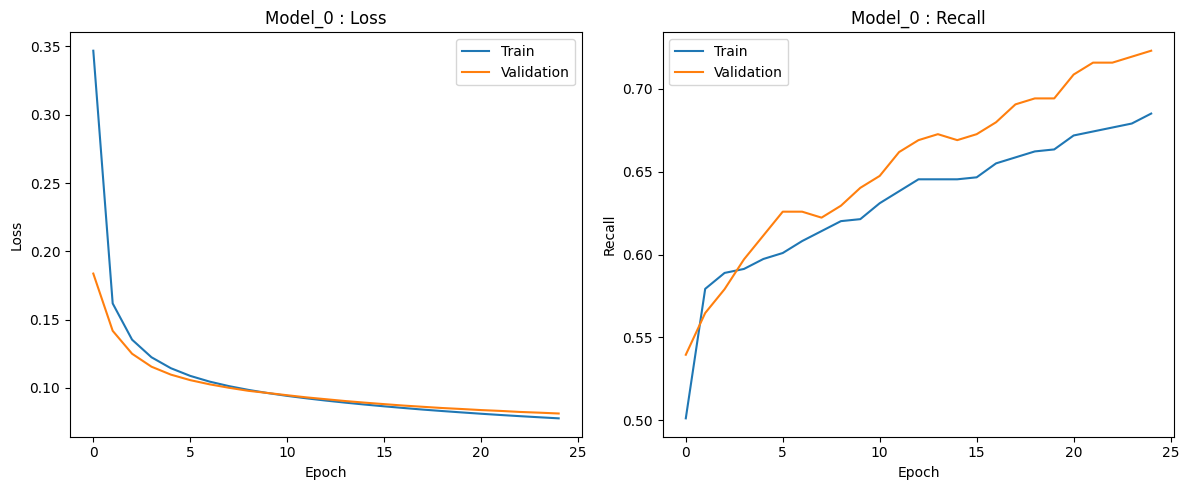

In [142]:
plot_loss_recall("Model_0", Model_0_history)

In [143]:
Model_0_results = ModelResults(
    Model_0_history,
    num_layers_hidden,
    num_neurons_hidden,
    act_fun_hidden,
    epochs,
    batch_size,
    end_time - start_time,
)

Model_0_df_results = add_model_results_to_dataframe(df_results, Model_0_results)
Model_0_df_results.T

,0
# hidden layers,1
# neurons - hidden layer,[32]
activation function - hidden layer,[tanh]
# epochs,25
batch size,100
train loss,0.078
validation loss,0.081
train recall,0.685
validation recall,0.723
time (secs),3.670


In [144]:
y_train_pred = Model_0.predict(X_train)
y_val_pred = Model_0.predict(X_val)

print("Classification Report - Train data",end="\n\n")
cr_train = classification_report(y_train,y_train_pred>0.5, output_dict=True)
#print(cr_train)
df_train = pd.DataFrame(cr_train)
print(df_train.T)

print("Classification Report - Validation data",end="\n\n")
cr_val = classification_report(y_val,y_val_pred>0.5,output_dict=True)
#print(cr_val)
df_val = pd.DataFrame(cr_val)
print(df_val.T)

469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 453us/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 423us/step
Classification Report - Train data

              precision  recall  f1-score   support
0                 0.982   0.996     0.989 14168.000
1                 0.908   0.689     0.783   832.000
accuracy          0.979   0.979     0.979     0.979
macro avg         0.945   0.842     0.886 15000.000
weighted avg      0.978   0.979     0.977 15000.000
Classification Report - Validation data

              precision  recall  f1-score  support
0                 0.984   0.995     0.989 4722.000
1                 0.893   0.723     0.799  278.000
accuracy          0.980   0.980     0.980    0.980
macro avg         0.939   0.859     0.894 5000.000
weighted avg      0.979   0.980     0.979 5000.000


In [145]:
#Post training performance metrics
Model_0_df_perf_train = model_performance_classification(
    Model_0, X_train, y_train, threshold=0.5)
Model_0_df_perf_train["Model"] = "Model_0" + "_train"
Model_0_df_perf_train.set_index("Model", inplace=True)
Model_0_df_perf_val = model_performance_classification(
    Model_0, X_val, y_val, threshold=0.5)
Model_0_df_perf_val["Model"] = "Model_0" + "_val"
Model_0_df_perf_val.set_index("Model", inplace=True)
Model_0_df_perf = pd.concat([Model_0_df_perf_train, Model_0_df_perf_val], axis=0)
print(Model_0_df_perf)
print("_" * 60)

469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 439us/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 427us/step
               Accuracy  Recall  Precision  F1 Score
Model                                               
Model_0_train     0.979   0.842      0.945     0.886
Model_0_val       0.980   0.859      0.939     0.894
____________________________________________________________


# **Model Performance Improvement**

## Model 1

In [146]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

### Model_1 - Architecture

In [147]:
# Input Layer
# - Automatically set by specifying input_dim
# - Number of neurons in the input layer - Number of predictors-X_train.shape[1]

# Hidden layers
num_layers_hidden = 2
num_neurons_hidden = [32, 16]  # Number of neurons in each hidden layer as a list
act_fun_hidden = ["tanh", "relu"]  # Activation functions to be used with hidden layers

# Output layer
num_neurons_output = 1  # Number of neurons  - 1 for binary classification
act_fun_out = "sigmoid"  # Activation function to be used with hidden layers

# compile() parameters
loss_fun = "binary_crossentropy"  # Loss function
opt_method = tf.keras.optimizers.SGD(momentum=0.9)  # Optimizer
eval_metric = ["recall"]  # Performance metric

# fit() parameters
epochs = 25  # set number of epochs to be used in the model
batch_size = 100  # set the batch size to be used in the model

### Model_1 - BuildModel

In [148]:
# Build Sequential model
Model_1 = tf.keras.models.Sequential()
# First hidden layer (Input layer is automatically added)
Model_1.add( Dense( num_neurons_hidden[0], activation=act_fun_hidden[0], input_dim=X_train.shape[1]))
Model_1.add( Dense( num_neurons_hidden[1], activation=act_fun_hidden[1])
)
Model_1.add(Dense(num_neurons_output, activation=act_fun_out))


# Compile Model
Model_1.compile(loss=loss_fun, optimizer=opt_method, metrics=eval_metric)

# Fit Model
start_time = time.time()
Model_1_history = Model_1.fit(
    X_train,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_val, y_val),
    class_weight=class_weight_dict
)
end_time = time.time()
print("Time taken in seconds ", end_time - start_time)

Epoch 1/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.7975 - recall: 0.8115 - val_loss: 0.1925 - val_recall: 0.8849
Epoch 2/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 895us/step - loss: 0.4536 - recall: 0.8992 - val_loss: 0.2026 - val_recall: 0.8777
Epoch 3/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 788us/step - loss: 0.3502 - recall: 0.9198 - val_loss: 0.1822 - val_recall: 0.8885
Epoch 4/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 838us/step - loss: 0.3805 - recall: 0.8998 - val_loss: 0.1269 - val_recall: 0.8849
Epoch 5/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 782us/step - loss: 0.3821 - recall: 0.8835 - val_loss: 0.1899 - val_recall: 0.8993
Epoch 6/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 995us/step - loss: 0.3510 - recall: 0.9051 - val_loss: 0.1102 - val_recall: 0.8849
Epoch 7/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 832us/step - loss: 0.2728 - recall: 0.9348 - val_loss: 0.1632 - val_recall: 0.8885
Epoch 8/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 782us/step - loss: 0.3249 - recall: 0.9166 - val_loss: 0.1075 - val_recall: 0

In [149]:
Model_1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         1,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,716 (14.52 KB)

 Trainable params: 1,857 (7.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,859 (7.27 KB)

### Model_1 - Results

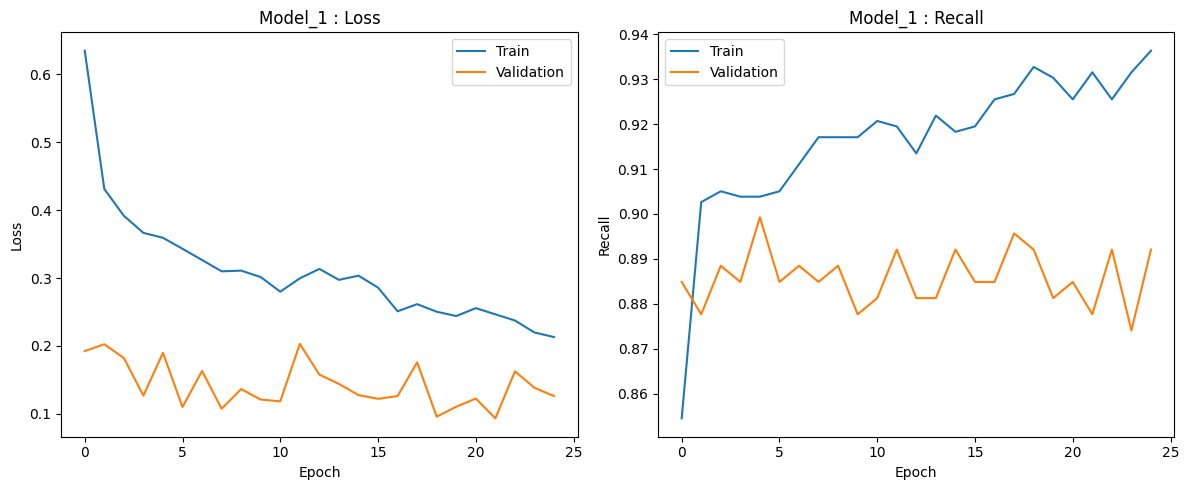

In [150]:
plot_loss_recall("Model_1", Model_1_history)

In [151]:
Model_1_results = ModelResults(
    Model_1_history,
    num_layers_hidden,
    num_neurons_hidden,
    act_fun_hidden,
    epochs,
    batch_size,
    end_time - start_time,
)
Model_1_df_results = add_model_results_to_dataframe(df_results, Model_1_results)
Model_1_df_results.T

,0
# hidden layers,2
# neurons - hidden layer,"[32, 16]"
activation function - hidden layer,"[tanh, relu]"
# epochs,25
batch size,100
train loss,0.213
validation loss,0.126
train recall,0.936
validation recall,0.892
time (secs),4.130


In [152]:
y_train_pred = Model_1.predict(X_train)
y_val_pred = Model_1.predict(X_val)

print("Classification Report - Train data",end="\n\n")
cr_train = classification_report(y_train,y_train_pred>0.5, output_dict=True)
#print(cr_train)
df_train = pd.DataFrame(cr_train)
print(df_train.T)

print("Classification Report - Validation data",end="\n\n")
cr_val = classification_report(y_val,y_val_pred>0.5,output_dict=True)
#print(cr_val)
df_val = pd.DataFrame(cr_val)
print(df_val.T)

469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 499us/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 422us/step
Classification Report - Train data

              precision  recall  f1-score   support
0                 0.997   0.982     0.989 14168.000
1                 0.756   0.947     0.841   832.000
accuracy          0.980   0.980     0.980     0.980
macro avg         0.877   0.965     0.915 15000.000
weighted avg      0.984   0.980     0.981 15000.000
Classification Report - Validation data

              precision  recall  f1-score  support
0                 0.994   0.976     0.985 4722.000
1                 0.683   0.892     0.774  278.000
accuracy          0.971   0.971     0.971    0.971
macro avg         0.838   0.934     0.879 5000.000
weighted avg      0.976   0.971     0.973 5000.000


In [153]:
Model_1_df_perf_train = model_performance_classification(
    Model_1, X_train, y_train, threshold=0.5
)
Model_1_df_perf_train["Model"] = "Model_1" + "_train"
Model_1_df_perf_train.set_index("Model", inplace=True)
Model_1_df_perf_val = model_performance_classification(
    Model_1, X_val, y_val, threshold=0.5
)
Model_1_df_perf_val["Model"] = "Model_1" + "_val"
Model_1_df_perf_val.set_index("Model", inplace=True)
Model_1_df_perf = pd.concat([Model_1_df_perf_train, Model_1_df_perf_val], axis=0)
print(Model_1_df_perf)
print("_" * 60)

469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 433us/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 426us/step
               Accuracy  Recall  Precision  F1 Score
Model                                               
Model_1_train     0.980   0.965      0.877     0.915
Model_1_val       0.971   0.934      0.838     0.879
____________________________________________________________


## Model 2

In [154]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

### Model_2 - Architecture

In [155]:
# Input Layer
# - Automatically set by specifying input_dim
# - Number of neurons in the input layer - Number of predictors-X_train.shape[1]

# Hidden layers
num_layers_hidden = 3
num_neurons_hidden = [32, 16, 8]  # Number of neurons in each hidden layer as a list
act_fun_hidden = ["tanh", "relu", "relu"]  # Activation functions to be used with hidden layers
initializer = ["glorot_uniform", "he_normal", "he_normal"]

# Output layer
num_neurons_output = 1  # Number of neurons  - 1 for binary classification
act_fun_out = "sigmoid"  # Activation function to be used with hidden layers

# compile() parameters
loss_fun = "binary_crossentropy"  # Loss function
opt_method = "rmsprop"  # Optimizer
eval_metric = ["recall"]  # Performance metric

# fit() parameters
epochs = 25  # set number of epochs to be used in the model
batch_size = 100  # set the batch size to be used in the model

### Model_2 - BuildModel

In [156]:
# Build Sequential model
Model_2 = Sequential()
# First hidden layer (Input layer is automatically added)
Model_2.add( Dense(num_neurons_hidden[0],
        activation=act_fun_hidden[0],
        input_dim=X_train.shape[1],
        kernel_initializer=initializer[0]))
Model_2.add( Dense(num_neurons_hidden[1],
        activation=act_fun_hidden[1],
        kernel_initializer=initializer[1]))
Model_2.add( Dense(
        num_neurons_hidden[2],
        activation=act_fun_hidden[2],
        kernel_initializer=initializer[2]))
Model_2.add(Dense(num_neurons_output, activation=act_fun_out))


# Compile Model
Model_2.compile(loss=loss_fun, optimizer=opt_method, metrics=eval_metric)

# Fit Model
start_time = time.time()
Model_2_history = Model_2.fit(
    X_train,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_val, y_val),
    class_weight=class_weight_dict
)
end_time = time.time()
print("Time taken in seconds ", end_time - start_time)

Epoch 1/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.2266 - recall: 0.3618 - val_loss: 0.2669 - val_recall: 0.8453
Epoch 2/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 918us/step - loss: 0.6450 - recall: 0.8797 - val_loss: 0.2299 - val_recall: 0.8741
Epoch 3/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 902us/step - loss: 0.5112 - recall: 0.8902 - val_loss: 0.1904 - val_recall: 0.8885
Epoch 4/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 894us/step - loss: 0.4595 - recall: 0.9003 - val_loss: 0.1587 - val_recall: 0.8777
Epoch 5/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 783us/step - loss: 0.4168 - recall: 0.8984 - val_loss: 0.1491 - val_recall: 0.8777
Epoch 6/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 894us/step - loss: 0.3717 - recall: 0.9145 - val_loss: 0.1385 - val_recall: 0.8885
Epoch 7/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 894us/step - loss: 0.3817 - recall: 0.9072 - val_loss: 0.1348 - val_recall: 0.8957
Epoch 8/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 894us/step - loss: 0.3601 - recall: 0.9085 - val_loss: 0.1143 - val_recall: 0

In [157]:
Model_2.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         1,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,972 (15.52 KB)

 Trainable params: 1,985 (7.75 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,987 (7.77 KB)

### Model_2 - Results

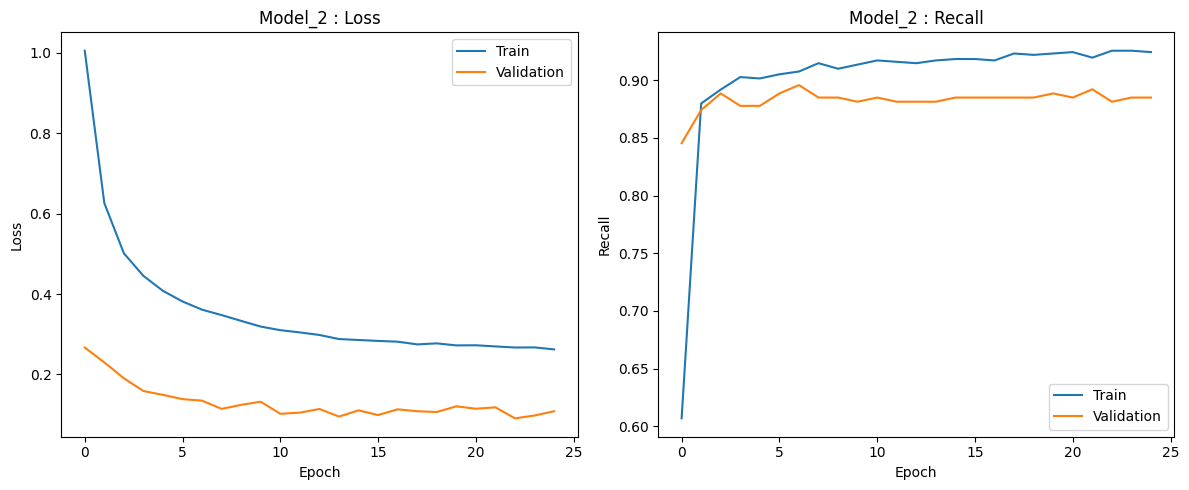

In [158]:
plot_loss_recall("Model_2", Model_2_history)

In [159]:
Model_2_results = ModelResults(
    Model_2_history,
    num_layers_hidden,
    num_neurons_hidden,
    act_fun_hidden,
    epochs,
    batch_size,
    end_time - start_time,
)
Model_2_df_results = add_model_results_to_dataframe(df_results, Model_2_results)
Model_2_df_results.T

,0
# hidden layers,3
# neurons - hidden layer,"[32, 16, 8]"
activation function - hidden layer,"[tanh, relu, relu]"
# epochs,25
batch size,100
train loss,0.262
validation loss,0.108
train recall,0.924
validation recall,0.885
time (secs),4.450


In [160]:
y_train_pred = Model_2.predict(X_train)
y_val_pred = Model_2.predict(X_val)

print("Classification Report - Train data",end="\n\n")
cr_train = classification_report(y_train,y_train_pred>0.5, output_dict=True)
#print(cr_train)
df_train = pd.DataFrame(cr_train)
print(df_train.T)

print("Classification Report - Validation data",end="\n\n")
cr_val = classification_report(y_val,y_val_pred>0.5,output_dict=True)
#print(cr_val)
df_val = pd.DataFrame(cr_val)
print(df_val.T)

469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 502us/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 533us/step
Classification Report - Train data

              precision  recall  f1-score   support
0                 0.996   0.991     0.994 14168.000
1                 0.861   0.934     0.896   832.000
accuracy          0.988   0.988     0.988     0.988
macro avg         0.929   0.963     0.945 15000.000
weighted avg      0.989   0.988     0.988 15000.000
Classification Report - Validation data

              precision  recall  f1-score  support
0                 0.993   0.988     0.991 4722.000
1                 0.812   0.885     0.847  278.000
accuracy          0.982   0.982     0.982    0.982
macro avg         0.903   0.936     0.919 5000.000
weighted avg      0.983   0.982     0.983 5000.000


In [161]:
# Post training performance metrics
Model_2_df_perf_train = model_performance_classification(
    Model_2, X_train, y_train, threshold=0.5
)
Model_2_df_perf_train["Model"] = "Model_2" + "_train"
Model_2_df_perf_train.set_index("Model", inplace=True)
Model_2_df_perf_val = model_performance_classification(
    Model_2, X_val, y_val, threshold=0.5
)
Model_2_df_perf_val["Model"] = "Model_2" + "_val"
Model_2_df_perf_val.set_index("Model", inplace=True)
Model_2_df_perf = pd.concat([Model_2_df_perf_train, Model_2_df_perf_val], axis=0)
print(Model_2_df_perf)
print("_" * 60)

469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 465us/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 427us/step
               Accuracy  Recall  Precision  F1 Score
Model                                               
Model_2_train     0.988   0.963      0.929     0.945
Model_2_val       0.982   0.936      0.903     0.919
____________________________________________________________


## Model 3

In [162]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

### Model_3 - Architecture

In [163]:
# Input Layer
# - Automatically set by specifying input_dim
# - Number of neurons in the input layer - Number of predictors-X_train.shape[1]

# Hidden layers
num_layers_hidden = 2
num_neurons_hidden = [32, 16]  # Number of neurons in each hidden layer as a list
act_fun_hidden = [
    "relu",
    "leakyrelu",
]  # Activation functions to be used with hidden layers
initializer = ["he_normal", "he_normal"]

# Output layer
num_neurons_output = 1  # Number of neurons  - 1 for binary classification
act_fun_out = "sigmoid"  # Activation function to be used with hidden layers

# compile() parameters
loss_fun = "binary_crossentropy"  # Loss function
opt_method = tf.keras.optimizers.Adam(learning_rate=0.001)  # Optimizer
eval_metric = ["recall"]  # Performance metric

# fit() parameters
epochs = 25  # set number of epochs to be used in the model
batch_size = 100  # set the batch size to be used in the model

### Model_3 - BuildModel

In [164]:
# Build Sequential model
Model_3 = tf.keras.models.Sequential()
# First hidden layer (Input layer is automatically added)
Model_3.add(Dense( num_neurons_hidden[0],
        activation=act_fun_hidden[0],
        kernel_initializer=initializer[0],
        input_dim=X_train.shape[1]))
Model_3.add(Dense( num_neurons_hidden[1],
        activation=LeakyReLU(alpha=0.1),
        kernel_initializer=initializer[1]))
Model_3.add(Dense(num_neurons_output, activation=act_fun_out))


# Compile Model
Model_3.compile(loss=loss_fun, optimizer=opt_method, metrics=eval_metric)

# Fit Model
start_time = time.time()
Model_3_history = Model_3.fit(
    X_train,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_val, y_val),
    class_weight=class_weight_dict
)
end_time = time.time()
print("Time taken in seconds ", end_time - start_time)

Epoch 1/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 2.4510 - recall: 0.4132 - val_loss: 0.2907 - val_recall: 0.8489
Epoch 2/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 782us/step - loss: 0.6570 - recall: 0.8822 - val_loss: 0.2083 - val_recall: 0.8525
Epoch 3/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 781us/step - loss: 0.5740 - recall: 0.8898 - val_loss: 0.1805 - val_recall: 0.8597
Epoch 4/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 894us/step - loss: 0.5276 - recall: 0.8868 - val_loss: 0.2062 - val_recall: 0.8849
Epoch 5/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 827us/step - loss: 0.4687 - recall: 0.8964 - val_loss: 0.2065 - val_recall: 0.8921
Epoch 6/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 900us/step - loss: 0.4235 - recall: 0.9165 - val_loss: 0.1682 - val_recall: 0.8741
Epoch 7/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 782us/step - loss: 0.3887 - recall: 0.9107 - val_loss: 0.1473 - val_recall: 0.8741
Epoch 8/25
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 903us/step - loss: 0.3553 - recall: 0.9149 - val_loss: 0.2004 - val_recall: 0

In [165]:
Model_3.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         1,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,573 (21.77 KB)

 Trainable params: 1,857 (7.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 3,716 (14.52 KB)

### Model_3 - Results

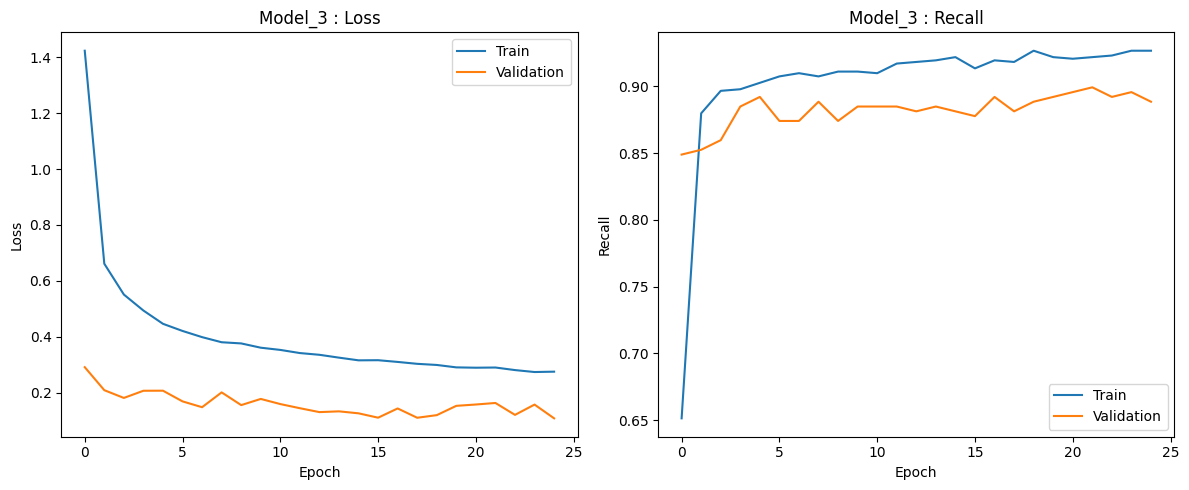

In [166]:
plot_loss_recall("Model_3", Model_3_history)

In [167]:
Model_3_results = ModelResults(
    Model_3_history,
    num_layers_hidden,
    num_neurons_hidden,
    act_fun_hidden,
    epochs,
    batch_size,
    end_time - start_time,
)
Model_3_df_results = add_model_results_to_dataframe(df_results, Model_3_results)
Model_3_df_results.T

,0
# hidden layers,2
# neurons - hidden layer,"[32, 16]"
activation function - hidden layer,"[relu, leakyrelu]"
# epochs,25
batch size,100
train loss,0.275
validation loss,0.107
train recall,0.927
validation recall,0.888
time (secs),4.450


In [168]:
y_train_pred = Model_3.predict(X_train)
y_val_pred = Model_3.predict(X_val)

print("Classification Report - Train data",end="\n\n")
cr_train = classification_report(y_train,y_train_pred>0.5, output_dict=True)
#print(cr_train)
df_train = pd.DataFrame(cr_train)
print(df_train.T)

print("Classification Report - Validation data",end="\n\n")
cr_val = classification_report(y_val,y_val_pred>0.5,output_dict=True)
#print(cr_val)
df_val = pd.DataFrame(cr_val)
print(df_val.T)

469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 430us/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 425us/step
Classification Report - Train data

              precision  recall  f1-score   support
0                 0.996   0.985     0.990 14168.000
1                 0.779   0.930     0.848   832.000
accuracy          0.982   0.982     0.982     0.982
macro avg         0.888   0.957     0.919 15000.000
weighted avg      0.984   0.982     0.982 15000.000
Classification Report - Validation data

              precision  recall  f1-score  support
0                 0.993   0.982     0.988 4722.000
1                 0.748   0.888     0.813  278.000
accuracy          0.977   0.977     0.977    0.977
macro avg         0.871   0.935     0.900 5000.000
weighted avg      0.980   0.977     0.978 5000.000


In [169]:
# Post training performance metrics
Model_3_df_perf_train = model_performance_classification(
    Model_3, X_train, y_train, threshold=0.5
)
Model_3_df_perf_train["Model"] = "Model_3" + "_train"
Model_3_df_perf_train.set_index("Model", inplace=True)
Model_3_df_perf_val = model_performance_classification(
    Model_3, X_val, y_val, threshold=0.5
)
Model_3_df_perf_val["Model"] = "Model_3" + "_val"
Model_3_df_perf_val.set_index("Model", inplace=True)
Model_3_df_perf = pd.concat([Model_3_df_perf_train, Model_3_df_perf_val], axis=0)
print(Model_3_df_perf)
print("_" * 60)

469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 426us/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 433us/step
               Accuracy  Recall  Precision  F1 Score
Model                                               
Model_3_train     0.982   0.957      0.888     0.919
Model_3_val       0.977   0.935      0.871     0.900
____________________________________________________________


## Model 4

In [170]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

### Model_4 - Architecture

In [171]:
# Input Layer
# - Automatically set by specifying input_dim
# - Number of neurons in the input layer - Number of predictors-X_train.shape[1]

# Hidden layers
num_layers_hidden = 3
num_neurons_hidden = [32, 16, 8]  # Number of neurons in each hidden layer as a list
act_fun_hidden = [
    "tanh",
    "relu",
    "relu",
]  # Activation functions to be used with hidden layers
initializer = ["glorot_uniform", "he_normal", "he_normal"]

# Output layer
num_neurons_output = 1  # Number of neurons  - 1 for binary classification
act_fun_out = "sigmoid"  # Activation function to be used with hidden layers

# compile() parameters
loss_fun = "binary_crossentropy"  # Loss function
opt_method = tf.keras.optimizers.Adam(learning_rate=0.0001)  # Optimizer
eval_metric = ["recall"]  # Performance metric

# fit() parameters
epochs = 50  # set number of epochs to be used in the model
batch_size = 200  # set the batch size to be used in the model

### Model_4 - BuildModel

In [172]:
# Build Sequential model
Model_4 = tf.keras.models.Sequential()
# First hidden layer (Input layer is automatically added)
Model_4.add(
    Dense(
        num_neurons_hidden[0],
        activation=act_fun_hidden[0],
        input_dim=X_train.shape[1],
        kernel_initializer=initializer[0]
    )
)
Model_4.add(BatchNormalization())
Model_4.add(
    Dense(
        num_neurons_hidden[1],
        activation=act_fun_hidden[1],
        kernel_initializer=initializer[1]
    )
)
Model_4.add(BatchNormalization())
Model_4.add(
    Dense(
        num_neurons_hidden[2],
        activation=act_fun_hidden[2],
        kernel_initializer=initializer[2]
    )
)
Model_4.add(BatchNormalization())

Model_4.add(Dense(num_neurons_output, activation=act_fun_out))


# Compile Model
Model_4.compile(loss=loss_fun, optimizer=opt_method, metrics=eval_metric)

# Fit Model
start_time = time.time()
Model_4_history = Model_4.fit(
    X_train,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_val, y_val),
    class_weight=class_weight_dict
)
end_time = time.time()
print("Time taken in seconds ", end_time - start_time)

Epoch 1/50
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 1.5332 - recall: 0.5932 - val_loss: 0.6966 - val_recall: 0.6259
Epoch 2/50
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.3385 - recall: 0.7113 - val_loss: 0.6769 - val_recall: 0.7302
Epoch 3/50
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.1941 - recall: 0.8455 - val_loss: 0.6634 - val_recall: 0.8094
Epoch 4/50
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.0650 - recall: 0.9064 - val_loss: 0.6525 - val_recall: 0.8525
Epoch 5/50
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.0504 - recall: 0.8946 - val_loss: 0.6409 - val_recall: 0.8777
Epoch 6/50
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9588 - recall: 0.9197 - val_loss: 0.6243 - val_recall: 0.8849
Epoch 7/50
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9186 - recall: 0.9198 - val_loss: 0.6066 - val_recall: 0.8849
Epoch 8/50
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.8962 - recall: 0.9250 - val_loss: 0.5874 - val_recall: 0.8885
Epoch 9/50
75/75 ━━━━━━━

In [173]:
Model_4.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         1,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8)              │            32 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,405 (25.02 KB)

 Trainable params: 2,097 (8.19 KB)

 Non-trainable params: 112 (448.00 B)

 Optimizer params: 4,196 (16.39 KB)

### Model_4 - Results

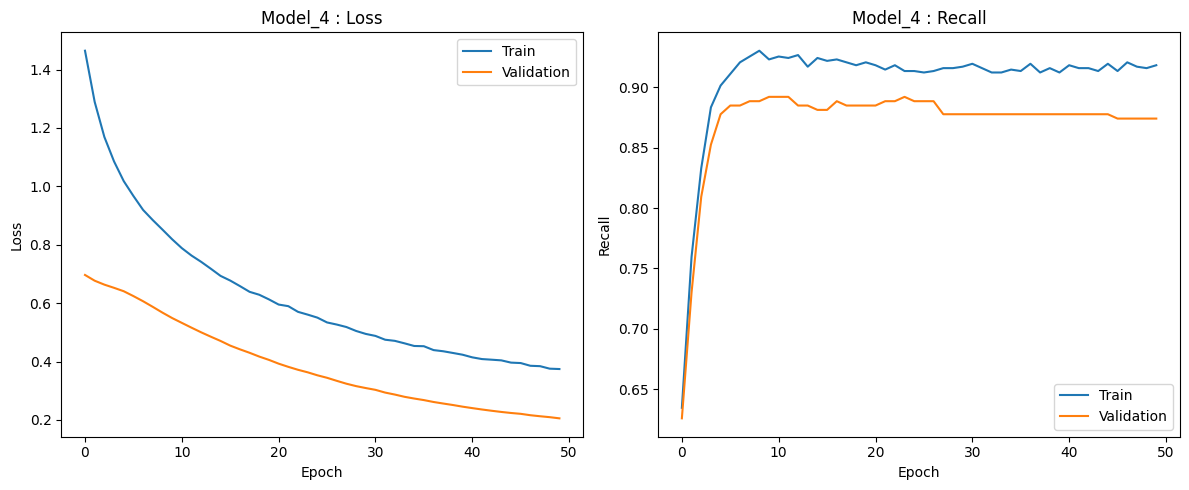

In [174]:
plot_loss_recall("Model_4", Model_4_history)

In [175]:
Model_4_results = ModelResults(
    Model_4_history,
    num_layers_hidden,
    num_neurons_hidden,
    act_fun_hidden,
    epochs,
    batch_size,
    end_time - start_time,
)
Model_4_df_results = add_model_results_to_dataframe(df_results, Model_4_results)
Model_4_df_results.T

,0
# hidden layers,3
# neurons - hidden layer,"[32, 16, 8]"
activation function - hidden layer,"[tanh, relu, relu]"
# epochs,50
batch size,200
train loss,0.374
validation loss,0.205
train recall,0.918
validation recall,0.874
time (secs),7.700


In [176]:
y_train_pred = Model_4.predict(X_train)
y_val_pred = Model_4.predict(X_val)

print("Classification Report - Train data",end="\n\n")
cr_train = classification_report(y_train,y_train_pred>0.5, output_dict=True)
#print(cr_train)
df_train = pd.DataFrame(cr_train)
print(df_train.T)

print("Classification Report - Validation data",end="\n\n")
cr_val = classification_report(y_val,y_val_pred>0.5,output_dict=True)
#print(cr_val)
df_val = pd.DataFrame(cr_val)
print(df_val.T)

469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 641us/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 537us/step
Classification Report - Train data

              precision  recall  f1-score   support
0                 0.995   0.965     0.980 14168.000
1                 0.607   0.922     0.732   832.000
accuracy          0.963   0.963     0.963     0.963
macro avg         0.801   0.943     0.856 15000.000
weighted avg      0.974   0.963     0.966 15000.000
Classification Report - Validation data

              precision  recall  f1-score  support
0                 0.992   0.959     0.975 4722.000
1                 0.556   0.874     0.680  278.000
accuracy          0.954   0.954     0.954    0.954
macro avg         0.774   0.917     0.828 5000.000
weighted avg      0.968   0.954     0.959 5000.000


In [177]:
# Post training performance metrics
Model_4_df_perf_train = model_performance_classification(
    Model_4, X_train, y_train, threshold=0.7
)
Model_4_df_perf_train["Model"] = "Model_4" + "_train"
Model_4_df_perf_train.set_index("Model", inplace=True)
Model_4_df_perf_val = model_performance_classification(
    Model_4, X_val, y_val, threshold=0.7
)
Model_4_df_perf_val["Model"] = "Model_4" + "_val"
Model_4_df_perf_val.set_index("Model", inplace=True)
Model_4_df_perf = pd.concat([Model_4_df_perf_train, Model_4_df_perf_val], axis=0)
print(Model_4_df_perf)
print("_" * 60)

469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 461us/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 441us/step
               Accuracy  Recall  Precision  F1 Score
Model                                               
Model_4_train     0.981   0.940      0.891     0.914
Model_4_val       0.977   0.915      0.876     0.894
____________________________________________________________


## Model 5

In [178]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

### Model_5 - Architecture

In [179]:
# Input Layer
# - Automatically set by specifying input_dim
# - Number of neurons in the input layer - Number of predictors-X_train.shape[1]

# Hidden layers
num_layers_hidden = 3
num_neurons_hidden = [32, 16, 8]  # Number of neurons in each hidden layer as a list
act_fun_hidden = [
    "tanh",
    "relu",
    "relu",
]  # Activation functions to be used with hidden layers
initializer = ["glorot_uniform", "he_normal", "he_normal"]

# Output layer
num_neurons_output = 1  # Number of neurons  - 1 for binary classification
act_fun_out = "sigmoid"  # Activation function to be used with hidden layers

# compile() parameters
loss_fun = "binary_crossentropy"  # Loss function
opt_method = tf.keras.optimizers.Adam(learning_rate=0.001)  # Optimizer
eval_metric = ["recall"]  # Performance metric

# fit() parameters
epochs = 50  # set number of epochs to be used in the model
batch_size = 200  # set the batch size to be used in the model

### Model_5 - BuildModel

In [180]:
# Build Sequential model
Model_5 = tf.keras.models.Sequential()
# First hidden layer (Input layer is automatically added)
Model_5.add(
    Dense(
        num_neurons_hidden[0],
        activation=act_fun_hidden[0],
        input_dim=X_train.shape[1],
        kernel_initializer=initializer[0]
    )
)
Model_5.add(BatchNormalization())
Model_5.add(Dropout(0.4))

Model_5.add(
    Dense(
        num_neurons_hidden[1],
        activation=act_fun_hidden[1],
        kernel_initializer=initializer[1]
    )
)
Model_5.add(BatchNormalization())
Model_5.add(Dropout(0.2))

Model_5.add(
    Dense(
        num_neurons_hidden[2],
        activation=act_fun_hidden[2],
        kernel_initializer=initializer[2]
    )
)
Model_5.add(BatchNormalization())
Model_5.add(Dropout(0.2))

Model_5.add(Dense(num_neurons_output, activation=act_fun_out))


# Compile Model
Model_5.compile(loss=loss_fun, optimizer=opt_method, metrics=eval_metric)

# Fit Model
start_time = time.time()
Model_5_history = Model_5.fit(
    X_train,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_val, y_val),
    class_weight=class_weight_dict
)
end_time = time.time()
print("Time taken in seconds ", end_time - start_time)

Epoch 1/50
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 1.4053 - recall: 0.6357 - val_loss: 0.5446 - val_recall: 0.8094
Epoch 2/50
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.0602 - recall: 0.7603 - val_loss: 0.4021 - val_recall: 0.8129
Epoch 3/50
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9738 - recall: 0.7524 - val_loss: 0.3566 - val_recall: 0.8417
Epoch 4/50
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8361 - recall: 0.8270 - val_loss: 0.3221 - val_recall: 0.8561
Epoch 5/50
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7821 - recall: 0.8126 - val_loss: 0.2981 - val_recall: 0.8561
Epoch 6/50
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7567 - recall: 0.8186 - val_loss: 0.2813 - val_recall: 0.8597
Epoch 7/50
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.6786 - recall: 0.8519 - val_loss: 0.2590 - val_recall: 0.8633
Epoch 8/50
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6677 - recall: 0.8532 - val_loss: 0.2430 - val_recall: 0.8597
Epoch 9/50
75/75 ━━━━━━━

In [181]:
Model_5.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         1,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8)              │            32 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,405 (25.02 KB)

 Trainable params: 2,097 (8.19 KB)

 Non-trainable params: 112 (448.00 B)

 Optimizer params: 4,196 (16.39 KB)

### Model_5 - Results

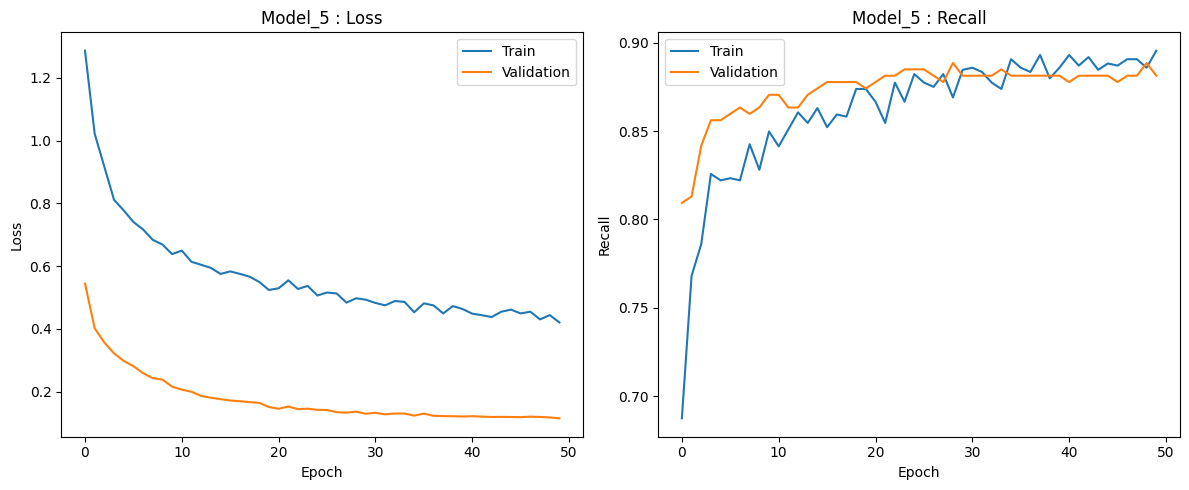

In [182]:
plot_loss_recall("Model_5", Model_5_history)

In [183]:
Model_5_results = ModelResults(
    Model_5_history,
    num_layers_hidden,
    num_neurons_hidden,
    act_fun_hidden,
    epochs,
    batch_size,
    end_time - start_time,
)
Model_5_df_results = add_model_results_to_dataframe(df_results, Model_5_results)
Model_5_df_results.T

,0
# hidden layers,3
# neurons - hidden layer,"[32, 16, 8]"
activation function - hidden layer,"[tanh, relu, relu]"
# epochs,50
batch size,200
train loss,0.421
validation loss,0.115
train recall,0.895
validation recall,0.881
time (secs),8.000


In [184]:
y_train_pred = Model_5.predict(X_train)
y_val_pred = Model_5.predict(X_val)

print("Classification Report - Train data",end="\n\n")
cr_train = classification_report(y_train,y_train_pred>0.5, output_dict=True)
#print(cr_train)
df_train = pd.DataFrame(cr_train)
print(df_train.T)

print("Classification Report - Validation data",end="\n\n")
cr_val = classification_report(y_val,y_val_pred>0.5,output_dict=True)
#print(cr_val)
df_val = pd.DataFrame(cr_val)
print(df_val.T)

469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 615us/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 659us/step
Classification Report - Train data

              precision  recall  f1-score   support
0                 0.995   0.990     0.992 14168.000
1                 0.841   0.911     0.875   832.000
accuracy          0.986   0.986     0.986     0.986
macro avg         0.918   0.950     0.934 15000.000
weighted avg      0.986   0.986     0.986 15000.000
Classification Report - Validation data

              precision  recall  f1-score  support
0                 0.993   0.990     0.991 4722.000
1                 0.833   0.881     0.857  278.000
accuracy          0.984   0.984     0.984    0.984
macro avg         0.913   0.935     0.924 5000.000
weighted avg      0.984   0.984     0.984 5000.000


In [185]:
# Post training performance metrics
Model_5_df_perf_train = model_performance_classification(
    Model_5, X_train, y_train, threshold=0.5
)
Model_5_df_perf_train["Model"] = "Model_5" + "_train"
Model_5_df_perf_train.set_index("Model", inplace=True)
Model_5_df_perf_val = model_performance_classification(
    Model_5, X_val, y_val, threshold=0.5
)
Model_5_df_perf_val["Model"] = "Model_5" + "_val"
Model_5_df_perf_val.set_index("Model", inplace=True)
Model_5_df_perf = pd.concat([Model_5_df_perf_train, Model_5_df_perf_val], axis=0)
print(Model_5_df_perf)
print("_" * 60)

469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 462us/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 533us/step
               Accuracy  Recall  Precision  F1 Score
Model                                               
Model_5_train     0.986   0.950      0.918     0.934
Model_5_val       0.984   0.935      0.913     0.924
____________________________________________________________


## Model 6

In [186]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

### Model_6 - Architecture

In [187]:
# Input Layer
# - Automatically set by specifying input_dim
# - Number of neurons in the input layer - Number of predictors-X_train.shape[1]

# Hidden layers
num_layers_hidden = 2
num_neurons_hidden = [16, 8]  # Number of neurons in each hidden layer as a list
act_fun_hidden = [
    "relu",
    "relu",
]  # Activation functions to be used with hidden layers
initializer = [ "he_normal", "he_normal"]

# Output layer
num_neurons_output = 1  # Number of neurons  - 1 for binary classification
act_fun_out = "sigmoid"  # Activation function to be used with hidden layers

# compile() parameters
loss_fun = "binary_crossentropy"  # Loss function
opt_method = tf.keras.optimizers.Adam(learning_rate=0.0001)  # Optimizer
eval_metric = ["recall"]  # Performance metric

# fit() parameters
epochs = 50  # set number of epochs to be used in the model
batch_size = 100  # set the batch size to be used in the model

### Model_6 - BuildModel

In [188]:
# Build Sequential model
Model_6 = tf.keras.models.Sequential()
# First hidden layer (Input layer is automatically added)
Model_6.add(
    Dense(
        num_neurons_hidden[0],
        activation=act_fun_hidden[0],
        input_dim=X_train.shape[1],
        kernel_initializer=initializer[0],
        kernel_regularizer=l1(0.01),
    )
)
Model_6.add(BatchNormalization())

Model_6.add(
    Dense(
        num_neurons_hidden[1],
        activation=act_fun_hidden[1],
        kernel_initializer=initializer[1],
        kernel_regularizer=l2(0.01),
    )
)
Model_6.add(BatchNormalization())

Model_6.add(Dense(num_neurons_output, activation=act_fun_out))


# Compile Model
Model_6.compile(loss=loss_fun, optimizer=opt_method, metrics=eval_metric)

# Fit Model
start_time = time.time()
Model_6_history = Model_6.fit(
    X_train,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_val, y_val),
    class_weight=class_weight_dict
)
end_time = time.time()
print("Time taken in seconds ", end_time - start_time)

Epoch 1/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 3.6068 - recall: 0.4286 - val_loss: 1.9920 - val_recall: 0.3885
Epoch 2/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 3.0944 - recall: 0.5478 - val_loss: 2.0028 - val_recall: 0.5899
Epoch 3/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 2.8755 - recall: 0.5988 - val_loss: 1.9796 - val_recall: 0.7158
Epoch 4/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 2.7289 - recall: 0.7108 - val_loss: 1.9489 - val_recall: 0.7662
Epoch 5/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 2.4766 - recall: 0.8060 - val_loss: 1.9187 - val_recall: 0.8058
Epoch 6/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 2.3839 - recall: 0.8049 - val_loss: 1.8829 - val_recall: 0.8417
Epoch 7/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 2.3112 - recall: 0.8571 - val_loss: 1.8455 - val_recall: 0.8597
Epoch 8/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 2.2168 - recall: 0.8755 - val_loss: 1.8064 - val_recall: 0.8705
Epoch 9/

In [189]:
Model_6.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 8)              │            32 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,597 (10.15 KB)

 Trainable params: 849 (3.32 KB)

 Non-trainable params: 48 (192.00 B)

 Optimizer params: 1,700 (6.64 KB)

### Model_6 - Results

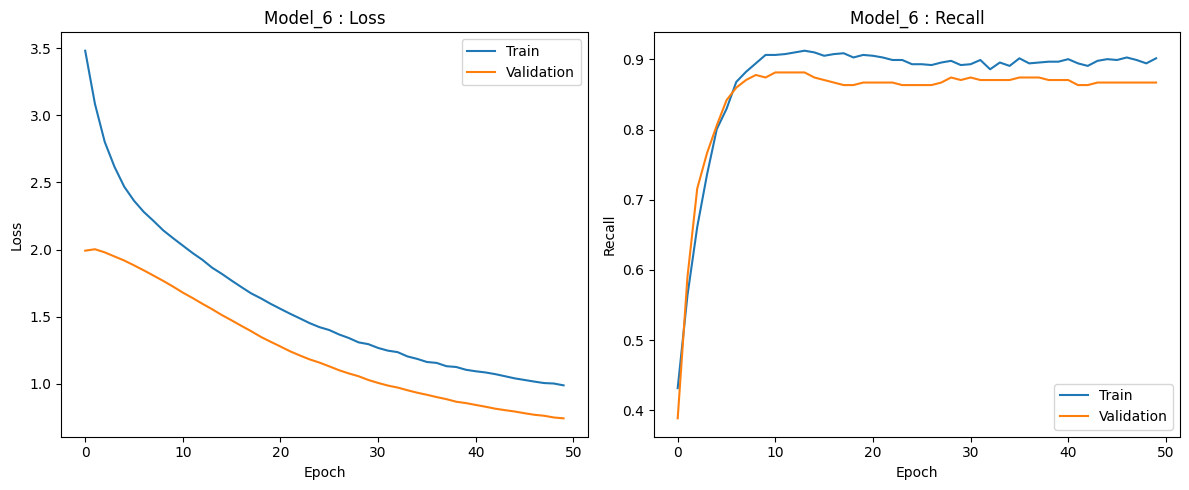

In [190]:
plot_loss_recall("Model_6", Model_6_history)

In [191]:
Model_6_results = ModelResults(
    Model_6_history,
    num_layers_hidden,
    num_neurons_hidden,
    act_fun_hidden,
    epochs,
    batch_size,
    end_time - start_time,
)
Model_6_df_results = add_model_results_to_dataframe(df_results, Model_6_results)
Model_6_df_results.T

,0
# hidden layers,2
# neurons - hidden layer,"[16, 8]"
activation function - hidden layer,"[relu, relu]"
# epochs,50
batch size,100
train loss,0.989
validation loss,0.743
train recall,0.901
validation recall,0.867
time (secs),10.080


In [192]:
y_train_pred = Model_6.predict(X_train)
y_val_pred = Model_6.predict(X_val)

print("Classification Report - Train data",end="\n\n")
cr_train = classification_report(y_train,y_train_pred>0.5, output_dict=True)
#print(cr_train)
df_train = pd.DataFrame(cr_train)
print(df_train.T)

print("Classification Report - Validation data",end="\n\n")
cr_val = classification_report(y_val,y_val_pred>0.5,output_dict=True)
#print(cr_val)
df_val = pd.DataFrame(cr_val)
print(df_val.T)

469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 551us/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 549us/step
Classification Report - Train data

              precision  recall  f1-score   support
0                 0.994   0.967     0.980 14168.000
1                 0.615   0.903     0.731   832.000
accuracy          0.963   0.963     0.963     0.963
macro avg         0.804   0.935     0.856 15000.000
weighted avg      0.973   0.963     0.966 15000.000
Classification Report - Validation data

              precision  recall  f1-score  support
0                 0.992   0.962     0.977 4722.000
1                 0.572   0.867     0.690  278.000
accuracy          0.957   0.957     0.957    0.957
macro avg         0.782   0.914     0.833 5000.000
weighted avg      0.969   0.957     0.961 5000.000


In [193]:
# Post training performance metrics
Model_6_df_perf_train = model_performance_classification(
    Model_6, X_train, y_train, threshold=0.5
)
Model_6_df_perf_train["Model"] = "Model_6" + "_train"
Model_6_df_perf_train.set_index("Model", inplace=True)
Model_6_df_perf_val = model_performance_classification(
    Model_6, X_val, y_val, threshold=0.5
)
Model_6_df_perf_val["Model"] = "Model_6" + "_val"
Model_6_df_perf_val.set_index("Model", inplace=True)
Model_6_df_perf = pd.concat([Model_6_df_perf_train, Model_6_df_perf_val], axis=0)
print(Model_6_df_perf)
print("_" * 60)

469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 443us/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 496us/step
               Accuracy  Recall  Precision  F1 Score
Model                                               
Model_6_train     0.963   0.935      0.804     0.856
Model_6_val       0.957   0.914      0.782     0.833
____________________________________________________________


## Model 7

In [194]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

### Model_7 - Architecture

In [195]:
# Input Layer
# - Automatically set by specifying input_dim
# - Number of neurons in the input layer - Number of predictors-X_train.shape[1]

# Hidden layers
num_layers_hidden = 2
num_neurons_hidden = [64, 32, 16]  # Number of neurons in each hidden layer as a list
act_fun_hidden = [
    "relu",
    "relu",
    "relu",
]  # Activation functions to be used with hidden layers
initializer = ["he_normal", "he_normal", "he_normal"]

# Output layer
num_neurons_output = 1  # Number of neurons  - 1 for binary classification
act_fun_out = "sigmoid"  # Activation function to be used with hidden layers

# compile() parameters
loss_fun = "binary_crossentropy"  # Loss function
opt_method = tf.keras.optimizers.Adam(learning_rate=0.0001)  # Optimizer
eval_metric = ["recall"]  # Performance metric

# fit() parameters
epochs = 50  # set number of epochs to be used in the model
batch_size = 100  # set the batch size to be used in the model

### Model_7 - BuildModel

In [196]:
# Build Sequential model
Model_7 = tf.keras.models.Sequential()
# First hidden layer (Input layer is automatically added)
Model_7.add(
    Dense(
        num_neurons_hidden[0],
        activation=act_fun_hidden[0],
        input_dim=X_train.shape[1],
        kernel_initializer=initializer[0],
        kernel_regularizer=l1(0.01),
    )
)
Model_7.add(BatchNormalization())

Model_7.add(
    Dense(
        num_neurons_hidden[1],
        activation=act_fun_hidden[1],
        kernel_initializer=initializer[1],
        kernel_regularizer=l2(0.01),
    )
)
Model_7.add(BatchNormalization())

Model_7.add(
    Dense(
        num_neurons_hidden[2],
        activation=act_fun_hidden[2],
        kernel_initializer=initializer[2],
        kernel_regularizer=l2(0.01),
    )
)
Model_7.add(BatchNormalization())

Model_7.add(Dense(num_neurons_output, activation=act_fun_out))


# Compile Model
Model_7.compile(loss=loss_fun, optimizer=opt_method, metrics=eval_metric)

# Fit Model
start_time = time.time()
Model_7_history = Model_7.fit(
    X_train,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_val, y_val),
    class_weight=class_weight_dict
)
end_time = time.time()
print("Time taken in seconds ", end_time - start_time)

Epoch 1/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 7.3790 - recall: 0.5500 - val_loss: 6.2007 - val_recall: 0.6223
Epoch 2/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 6.7579 - recall: 0.8357 - val_loss: 6.0892 - val_recall: 0.8489
Epoch 3/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 6.4287 - recall: 0.9016 - val_loss: 5.9547 - val_recall: 0.8993
Epoch 4/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 6.2157 - recall: 0.9388 - val_loss: 5.8005 - val_recall: 0.9029
Epoch 5/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 6.0398 - recall: 0.9253 - val_loss: 5.6401 - val_recall: 0.9029
Epoch 6/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 5.8216 - recall: 0.9377 - val_loss: 5.4775 - val_recall: 0.9029
Epoch 7/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 5.6910 - recall: 0.9261 - val_loss: 5.3131 - val_recall: 0.8993
Epoch 8/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 5.4937 - recall: 0.9323 - val_loss: 5.1510 - val_recall: 0.8957
Epoch 9/

In [197]:
Model_7.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,645 (65.02 KB)

 Trainable params: 5,473 (21.38 KB)

 Non-trainable params: 224 (896.00 B)

 Optimizer params: 10,948 (42.77 KB)

### Model_7 - Results

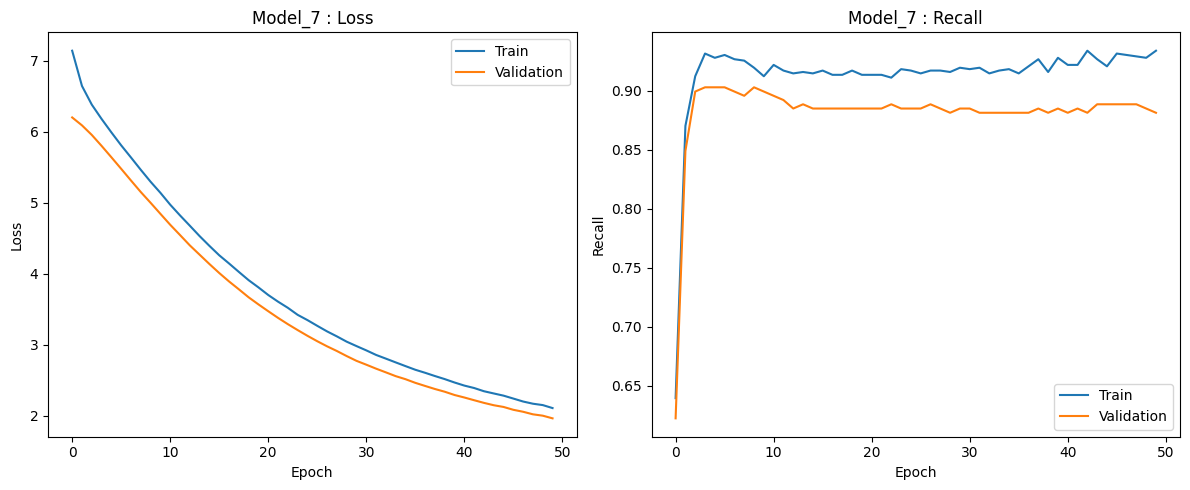

In [198]:
plot_loss_recall("Model_7", Model_7_history)

In [199]:
Model_7_results = ModelResults(
    Model_7_history,
    num_layers_hidden,
    num_neurons_hidden,
    act_fun_hidden,
    epochs,
    batch_size,
    end_time - start_time,
)
Model_7_df_results = add_model_results_to_dataframe(df_results, Model_7_results)
Model_7_df_results.T

,0
# hidden layers,2
# neurons - hidden layer,"[64, 32, 16]"
activation function - hidden layer,"[relu, relu, relu]"
# epochs,50
batch size,100
train loss,2.111
validation loss,1.967
train recall,0.934
validation recall,0.881
time (secs),12.720


In [200]:
y_train_pred = Model_7.predict(X_train)
y_val_pred = Model_7.predict(X_val)

print("Classification Report - Train data",end="\n\n")
cr_train = classification_report(y_train,y_train_pred>0.5, output_dict=True)
#print(cr_train)
df_train = pd.DataFrame(cr_train)
print(df_train.T)

print("Classification Report - Validation data",end="\n\n")
cr_val = classification_report(y_val,y_val_pred>0.5,output_dict=True)
#print(cr_val)
df_val = pd.DataFrame(cr_val)
print(df_val.T)


469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 712us/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 428us/step
Classification Report - Train data

              precision  recall  f1-score   support
0                 0.996   0.987     0.992 14168.000
1                 0.809   0.934     0.867   832.000
accuracy          0.984   0.984     0.984     0.984
macro avg         0.903   0.960     0.929 15000.000
weighted avg      0.986   0.984     0.985 15000.000
Classification Report - Validation data

              precision  recall  f1-score  support
0                 0.993   0.984     0.988 4722.000
1                 0.763   0.881     0.818  278.000
accuracy          0.978   0.978     0.978    0.978
macro avg         0.878   0.933     0.903 5000.000
weighted avg      0.980   0.978     0.979 5000.000


In [201]:
# Post training performance metrics
Model_7_df_perf_train = model_performance_classification(
    Model_7, X_train, y_train, threshold=0.5
)
Model_7_df_perf_train["Model"] = "Model_7" + "_train"
Model_7_df_perf_train.set_index("Model", inplace=True)
Model_7_df_perf_val = model_performance_classification(
    Model_7, X_val, y_val, threshold=0.5
)
Model_7_df_perf_val["Model"] = "Model_7" + "_val"
Model_7_df_perf_val.set_index("Model", inplace=True)
Model_7_df_perf = pd.concat([Model_7_df_perf_train, Model_7_df_perf_val], axis=0)
print(Model_7_df_perf)
print("_" * 60)

469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 511us/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 536us/step
               Accuracy  Recall  Precision  F1 Score
Model                                               
Model_7_train     0.984   0.960      0.903     0.929
Model_7_val       0.978   0.933      0.878     0.903
____________________________________________________________


# **Model Performance Comparison and Final Model Selection**

Now, in order to select the final model, we will compare the performances of all the models for the training and validation sets.

In [202]:
Model_df_results = add_model_results_to_dataframe(df_results, Model_0_results)
Model_df_results = add_model_results_to_dataframe(Model_df_results, Model_1_results)
Model_df_results = add_model_results_to_dataframe(Model_df_results, Model_2_results)
Model_df_results = add_model_results_to_dataframe(Model_df_results, Model_3_results)
Model_df_results = add_model_results_to_dataframe(Model_df_results, Model_4_results)
Model_df_results = add_model_results_to_dataframe(Model_df_results, Model_5_results)
Model_df_results = add_model_results_to_dataframe(Model_df_results, Model_6_results)
Model_df_results = add_model_results_to_dataframe(Model_df_results, Model_7_results)

Model_df_results.T

,0,1,2,3,4,5,6,7
# hidden layers,1,2,3,2,3,3,2,2
# neurons - hidden layer,[32],"[32, 16]","[32, 16, 8]","[32, 16]","[32, 16, 8]","[32, 16, 8]","[16, 8]","[64, 32, 16]"
activation function - hidden layer,[tanh],"[tanh, relu]","[tanh, relu, relu]","[relu, leakyrelu]","[tanh, relu, relu]","[tanh, relu, relu]","[relu, relu]","[relu, relu, relu]"
# epochs,25,25,25,25,50,50,50,50
batch size,100,100,100,100,200,200,100,100
train loss,0.078,0.213,0.262,0.275,0.374,0.421,0.989,2.111
validation loss,0.081,0.126,0.108,0.107,0.205,0.115,0.743,1.967
train recall,0.685,0.936,0.924,0.927,0.918,0.895,0.901,0.934
validation recall,0.723,0.892,0.885,0.888,0.874,0.881,0.867,0.881
time (secs),3.670,4.130,4.450,4.450,7.700,8.000,10.080,12.720


In [203]:
Models_Performance_df = pd.concat(
    [
        Model_0_df_perf,
        Model_1_df_perf,
        Model_2_df_perf,
        Model_3_df_perf,
        Model_4_df_perf,
        Model_5_df_perf,
        Model_6_df_perf,
        Model_7_df_perf
    ],
    axis=0,
)
print(Models_Performance_df)

               Accuracy  Recall  Precision  F1 Score
Model                                               
Model_0_train     0.979   0.842      0.945     0.886
Model_0_val       0.980   0.859      0.939     0.894
Model_1_train     0.980   0.965      0.877     0.915
Model_1_val       0.971   0.934      0.838     0.879
Model_2_train     0.988   0.963      0.929     0.945
Model_2_val       0.982   0.936      0.903     0.919
Model_3_train     0.982   0.957      0.888     0.919
Model_3_val       0.977   0.935      0.871     0.900
Model_4_train     0.981   0.940      0.891     0.914
Model_4_val       0.977   0.915      0.876     0.894
Model_5_train     0.986   0.950      0.918     0.934
Model_5_val       0.984   0.935      0.913     0.924
Model_6_train     0.963   0.935      0.804     0.856
Model_6_val       0.957   0.914      0.782     0.833
Model_7_train     0.984   0.960      0.903     0.929
Model_7_val       0.978   0.933      0.878     0.903


# Final Model

Now, let's check the performance of the final model on the test set.

- Final Model:
- Model_5 is chosen as the final model as this model showed **least overfitting**.
- train_recall(0.893) and validation_recall(0.885)
- Hence, this model will perform better on unseen data
- In this model **3 hidden layers** are used with the number of neurons in each layer as [32, 16, 8]
- This model used batch normalization and dropouts as well.
- Drop out values after each hidden layer are used as 04, 0.2, 0.2
- tanh, relu and relu activation functions are used
- ***glorot_unifrom*** initializer is used along when **tanh** is used and ***he_normal*** is used when **relu** activation is used.
- **Adam(learning_rate=0.001)** optimizer is used
- This is a binary classification problem,
  - only one neuron is used in the output layer,
  - sigmoid is used as the activation function for the output layer.
  - "binary_crossentropy" is chosen as the loss function
- **50 epochs**  with **batch size 200** is used


In [204]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

In [205]:
# Build Sequential model
Final_Model = tf.keras.models.Sequential()
# First hidden layer (Input layer is automatically added)
Final_Model.add(
    Dense(
        32,
        activation="tanh",
        input_dim=X_train.shape[1],
        kernel_initializer="glorot_uniform"
    )
)
Final_Model.add(BatchNormalization())
Final_Model.add(Dropout(0.4))

Final_Model.add(
    Dense(
        16,
        activation="relu",
        kernel_initializer="he_normal"
    )
)
Final_Model.add(BatchNormalization())
Final_Model.add(Dropout(0.2))

Final_Model.add(
    Dense(
        8,
        activation="relu",
        kernel_initializer="he_normal"
    )
)
Final_Model.add(BatchNormalization())
Final_Model.add(Dropout(0.2))

Final_Model.add(Dense(1, activation="sigmoid"))


# Compile Model
Final_Model.compile(loss="binary_crossentropy", optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), metrics=["recall"])

# Fit Model
start_time = time.time()
Final_Model_history = Final_Model.fit(
    X_train,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_val, y_val),
    class_weight=class_weight_dict
)
end_time = time.time()
print("Time taken in seconds ", end_time - start_time)

Epoch 1/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 1.3523 - recall: 0.6854 - val_loss: 0.3817 - val_recall: 0.7950
Epoch 2/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9534 - recall: 0.8145 - val_loss: 0.2940 - val_recall: 0.8417
Epoch 3/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7709 - recall: 0.8512 - val_loss: 0.2607 - val_recall: 0.8561
Epoch 4/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7304 - recall: 0.8403 - val_loss: 0.2357 - val_recall: 0.8561
Epoch 5/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.7142 - recall: 0.8365 - val_loss: 0.2212 - val_recall: 0.8669
Epoch 6/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.7081 - recall: 0.8356 - val_loss: 0.2021 - val_recall: 0.8705
Epoch 7/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.6677 - recall: 0.8333 - val_loss: 0.1764 - val_recall: 0.8705
Epoch 8/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.6228 - recall: 0.8595 - val_loss: 0.1633 - val_recall: 0.8741
Epoch 9/

In [206]:
y_train_pred = Final_Model.predict(X_train)
y_val_pred = Final_Model.predict(X_val)
y_test_pred = Final_Model.predict(X_test)

print("Classification Report - Train data",end="\n\n")
cr_train = classification_report(y_train,y_train_pred>0.5, output_dict=True)
#print(cr_train)
df_train = pd.DataFrame(cr_train)
print(df_train.T)

print("\nClassification Report - Validation data",end="\n\n")
cr_val = classification_report(y_val,y_val_pred>0.5,output_dict=True)
#print(cr_val)
df_val = pd.DataFrame(cr_val)
print(df_val.T)

print("\nClassification Report - Test data",end="\n\n")
cr_test = classification_report(y_test,y_test_pred>0.5,output_dict=True)
#print(cr_test)
df_test = pd.DataFrame(cr_test)
print(df_test.T)

469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 590us/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 534us/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 558us/step
Classification Report - Train data

              precision  recall  f1-score   support
0                 0.994   0.992     0.993 14168.000
1                 0.876   0.906     0.891   832.000
accuracy          0.988   0.988     0.988     0.988
macro avg         0.935   0.949     0.942 15000.000
weighted avg      0.988   0.988     0.988 15000.000

Classification Report - Validation data

              precision  recall  f1-score  support
0                 0.993   0.992     0.993 4722.000
1                 0.866   0.885     0.875  278.000
accuracy          0.986   0.986     0.986    0.986
macro avg         0.930   0.938     0.934 5000.000
weighted avg      0.986   0.986     0.986 5000.000

Classification Report - Test data

              precision  recall  f1-score  support
0                 0.992   0.993     0.993 4718.000
1                 0.884   0.869     0

In [207]:
Final_Model_df_perf_train = model_performance_classification(
    Final_Model, X_train, y_train, threshold=0.5
)
Final_Model_df_perf_train["Model"] = "Final_Model" + "_train"
Final_Model_df_perf_train.set_index("Model", inplace=True)

Final_Model_df_perf_val = model_performance_classification(
    Final_Model, X_val, y_val, threshold=0.5
)
Final_Model_df_perf_val["Model"] = "Final_Model" + "_val"
Final_Model_df_perf_val.set_index("Model", inplace=True)

Final_Model_df_perf_test = model_performance_classification(
    Final_Model, X_test, y_test, threshold=0.5
)
Final_Model_df_perf_test["Model"] = "Final_Model" + "_test"
Final_Model_df_perf_test.set_index("Model", inplace=True)

Final_Model_df_perf = pd.concat([Final_Model_df_perf_train, Final_Model_df_perf_val, Final_Model_df_perf_test], axis=0)
print(Final_Model_df_perf)
print("_" * 60)

469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 532us/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 507us/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 508us/step
                   Accuracy  Recall  Precision  F1 Score
Model                                                   
Final_Model_train     0.988   0.949      0.935     0.942
Final_Model_val       0.986   0.938      0.930     0.934
Final_Model_test      0.986   0.931      0.938     0.935
____________________________________________________________


# **Actionable Insights and Recommendations**

- A thorough Univariate and Bi-variate analysis is performed.
  - Predictors for which **Higher values are most likely lead to potential failure** .
    - **V1, V4, V7, V8, V11, V14, V15, V16, V21, V28, V29, V34**
  - Predictors for which, **Lower values associate with potential failure**.
    - **V3, V5, V10, V13, V18, V22, V24, V26, V31, V33, V35, V36, V39**
- The features are masked in the given data set. Insights can be interpreted by using respective actual features.

- Target class imbalance is accounted for by using class weights
  - Techniques like undersampling the majority class and oversampling minority classes can also be used to account for the imbalance
- Replacement cost > repair cost, hence,
  - **Recall** metric is used as the evaluation criterion as predicting the failures correctly is most important for business.
  - Evaluation metrics F1-score can also be used if predicting both the failure and no failure classes is the priority

- As some of the features have correlation, dimensionality reduction techniques like PCA can be tried. In this analysis, regularization is employed to account for this as L1 regularization also helps in feature selection.
- A total of 7 models with selection of variety of architecture, activation functions and optimizers, initializers are performed.
- The model which resulted in the least over fitting and has an ability to perform well on the unseen data is selected as the final model.
- The final model showed good performance on the test data as well.